### LIBRARIES

In [1]:
import jax
import jax.numpy as jnp
from jax import jit, vmap
from jax import lax
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import os
import pickle
from sklearn.covariance import LedoitWolf
import seaborn as sns

In [2]:
!pip install mygene --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.3 MB/s eta 0:00:00


In [3]:
!pip install gseapy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 634.7/634.7 kB 11.9 MB/s eta 0:00:00


In [4]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import os
import pickle
from sklearn.covariance import LedoitWolf
import seaborn as sns
import time
import gseapy as gp
import mygene
from matplotlib_venn import venn3

# tDNA

In [12]:
def altra(v, ind, nodes):
    """
    Proximal operator for tree-structured group Lasso.
    Direct translation of altra.h. from the SLEP package
    """
    n = len(v)
    x = np.copy(v)

    # Special node: elementwise L1 shrink
    if nodes > 0 and int(ind[0, 0]) == -1 and int(ind[1, 0]) == -1:
      lam = ind[2, 0]
      for j in range(n):
          if v[j] > lam:
              x[j] = v[j] - lam
          elif v[j] < -lam:
              x[j] = v[j] + lam
          else:
              x[j] = 0.0
      i0 = 1
    else:
      x[:] = v
      i0 = 0

    # Group shrink for internal + root nodes
    for i in range(i0, nodes):
        start = int(ind[0, i]) - 1
        end = int(ind[1, i])
        lam = ind[2, i]

        group = x[start:end]
        two_norm = np.linalg.norm(group)

        if two_norm > lam and two_norm > 0:
            ratio = (two_norm - lam) / two_norm
            x[start:end] = group * ratio
        else:
            x[start:end] = 0.0

    return x



def tree_structured_proximal_operator(Y, lambda_val, omega1, omega2, omega3):
    K_minus_1 = len(Y)
    p = Y[0].shape[0]
    V = [Y_k.copy() for Y_k in Y]

    # Build index structure: 1 L1 node + (K-1) stage groups + 1 root
    nodes = K_minus_1 + 2
    ind = np.zeros((3, nodes))

    # Special L1 node
    ind[:, 0] = [-1.0, -1.0, lambda_val * omega1]

    # Stage groups (children) - vectorized
    k_indices = np.arange(K_minus_1)
    ind[0, 1:K_minus_1+1] = k_indices * p + 1
    ind[1, 1:K_minus_1+1] = (k_indices + 1) * p
    ind[2, 1:K_minus_1+1] = lambda_val * omega2

    # Root group (parent)
    ind[0, K_minus_1 + 1] = 1
    ind[1, K_minus_1 + 1] = K_minus_1 * p
    ind[2, K_minus_1 + 1] = lambda_val * omega3

    # Pre-concatenate all Y matrices
    Y_concat = np.vstack([Y_k for Y_k in Y])

    # Process all columns at once
    X_concat = np.zeros_like(Y_concat)
    for j in range(p):
        X_concat[:, j] = altra(Y_concat[:, j], ind, nodes)

    # Redistribute back into matrices
    for k in range(K_minus_1):
        V[k] = X_concat[k * p:(k + 1) * p, :]

    return V

def d_trace_loss_gradient(V_list, S_hat_list):
    K = len(S_hat_list)
    grad_list = []
    for k in range(K - 1):
        S_k = S_hat_list[k]
        S_kp1 = S_hat_list[k + 1]
        Dk = V_list[k] + V_list[k].T
        grad = S_k @ Dk @ S_kp1 + S_kp1 @ Dk @ S_k - 2.0 * (S_k - S_kp1)
        grad_list.append(grad)
    return grad_list


def d_trace_loss(V_list, S_hat_list):
    K = len(S_hat_list)
    total = 0.0
    for k in range(K - 1):
        S_k = S_hat_list[k]
        S_kp1 = S_hat_list[k + 1]
        Dk = V_list[k] + V_list[k].T

        term1 = 0.25 * np.sum((S_k @ Dk) * (Dk @ S_kp1))
        term2 = 0.25 * np.sum((S_kp1 @ Dk) * (Dk @ S_k))
        term3 = np.sum(Dk*(S_k - S_kp1))
        total += term1 + term2 - term3
    return total


def tree_norm(V_list, omega_1, omega_2, omega_3):
    p = V_list[0].shape[0]
    penalty = 0.0

    # Leaf nodes - vectorized L1 norm
    penalty += omega_1 * sum(np.sum(np.abs(V_k)) for V_k in V_list)

    # Internal nodes - vectorized L2 norms per column
    penalty += omega_2 * sum(np.sum(np.linalg.norm(V_k, axis=0)) for V_k in V_list)

    # Root node
    col_norms_squared = np.zeros(p)
    for V_k in V_list:
        col_norms_squared += np.sum(V_k ** 2, axis=0)
    penalty += omega_3 * np.sum(np.sqrt(col_norms_squared))

    return penalty


def tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, omega1, omega2, omega3,max_iter=1000):
    K = len(S_hat_list)
    p = S_hat_list[0].shape[0]

    V_list = [np.zeros((p, p)) for _ in range(K - 1)]
    V_old_list = [V.copy() for V in V_list]

    # initialize Y_list as copies
    Y_list = [V.copy() for V in V_list]

    history = {'objective': [], 'loss': [], 'penalty': []}

    for t in range(1, max_iter+1):

        m = t/(t + 3.0)
        Y_list = [V_list[k] + m * (V_list[k] - V_old_list[k]) for k in range(K - 1)]

        # store old
        V_old_list = [V.copy() for V in V_list]

        # gradient at Y
        grad_list = d_trace_loss_gradient(Y_list, S_hat_list)
        alpha = 1.0

        for _ in range(100):
            # gradient step
            A_list = [Y_list[k] - alpha * grad_list[k] for k in range(K - 1)]

            # proximal
            Z_list = tree_structured_proximal_operator(A_list, lambda_val * alpha, omega1, omega2, omega3)

            loss_Y = d_trace_loss(Y_list, S_hat_list)
            loss_Z = d_trace_loss(Z_list, S_hat_list)

            grad_diff = sum(np.trace(grad_list[k] @ (Z_list[k] - Y_list[k])) for k in range(K - 1))

            quad_term = sum(np.sum((Z_list[k] - Y_list[k]) ** 2) for k in range(K - 1)) / (2 * alpha)

            if loss_Z <= loss_Y + grad_diff + quad_term :
                break
            alpha *= 0.5
        else:
            print(f"Failed to converge at iteration {t}; proceeding with current Z")

        V_list = Z_list

        # objective
        loss = d_trace_loss(V_list, S_hat_list)
        penalty = tree_norm(V_list, omega1, omega2, omega3)
        objective = loss + lambda_val * penalty

        history['objective'].append(objective)
        history['loss'].append(loss)
        history['penalty'].append(penalty)

        # convergence check
        if len(history['objective']) > 1:
            obj_change = abs(history['objective'][-1] - history['objective'][-2])
            if obj_change <= 0.0001 * abs(history['objective'][-2]):
                break

        if t<11 or t%50==0:
          print(f"Iter {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")
       # if (t % 20 == 0 and t<201) or t<11 or (t%50==0 and t>200):
       #   print(f"Iter {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    D_list = [V + V.T for V in V_list]
    print(f"\n Completed at iteration {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")
    return V_list, D_list, history

# tDNA v2 (piu veloce)

In [13]:
def altra(v, ind, nodes):
    """
    Proximal operator for tree-structured group Lasso.
    Direct translation of altra.h. from the SLEP package
    """
    n = len(v)
    x = np.copy(v)

    # Special node: elementwise L1 shrink
    if nodes > 0 and int(ind[0, 0]) == -1 and int(ind[1, 0]) == -1:
        lam = ind[2, 0]
        for j in range(n):
            if v[j] > lam:
                x[j] = v[j] - lam
            elif v[j] < -lam:
                x[j] = v[j] + lam
            else:
                x[j] = 0.0
        i0 = 1
    else:
        x[:] = v
        i0 = 0

    # Group shrink for internal + root nodes
    for i in range(i0, nodes):
        start = int(ind[0, i]) - 1
        end = int(ind[1, i])
        lam = ind[2, i]

        group = x[start:end]
        two_norm = np.linalg.norm(group)

        if two_norm > lam and two_norm > 0:
            ratio = (two_norm - lam) / two_norm
            x[start:end] = group * ratio
        else:
            x[start:end] = 0.0

    return x


def tree_structured_proximal_operator(Y, lambda_val, omega1, omega2, omega3):
    K_minus_1 = len(Y)
    p = Y[0].shape[0]
    V = [Y_k.copy() for Y_k in Y]

    # Build index structure: 1 L1 node + (K-1) stage groups + 1 root
    nodes = K_minus_1 + 2
    ind = np.zeros((3, nodes))

    # Special L1 node
    ind[:, 0] = [-1.0, -1.0, lambda_val * omega1]

    # Stage groups (children)
    k_indices = np.arange(K_minus_1)
    ind[0, 1:K_minus_1+1] = k_indices * p + 1
    ind[1, 1:K_minus_1+1] = (k_indices + 1) * p
    ind[2, 1:K_minus_1+1] = lambda_val * omega2

    # Root group (parent)
    ind[0, K_minus_1 + 1] = 1
    ind[1, K_minus_1 + 1] = K_minus_1 * p
    ind[2, K_minus_1 + 1] = lambda_val * omega3

    # Pre-concatenate all Y matrices (avoids repeated stacking)
    Y_concat = np.vstack([Y_k for Y_k in Y])

    # Process all columns at once
    X_concat = np.zeros_like(Y_concat)
    for j in range(p):
        X_concat[:, j] = altra(Y_concat[:, j], ind, nodes)

    # Redistribute back into matrices
    for k in range(K_minus_1):
        V[k] = X_concat[k * p:(k + 1) * p, :]

    return V


def d_trace_loss_gradient(V_list, S_hat_list):
    K = len(S_hat_list)
    grad_list = []
    for k in range(K - 1):
        S_k = S_hat_list[k]
        S_kp1 = S_hat_list[k + 1]
        Dk = V_list[k] + V_list[k].T
        grad = S_k @ Dk @ S_kp1 + S_kp1 @ Dk @ S_k - 2.0 * (S_k - S_kp1)
        grad_list.append(grad)
    return grad_list


def d_trace_loss(V_list, S_hat_list):
    K = len(S_hat_list)
    total = 0.0
    for k in range(K - 1):
        S_k = S_hat_list[k]
        S_kp1 = S_hat_list[k + 1]
        Dk = V_list[k] + V_list[k].T

        term1 = 0.25 * np.sum((S_k @ Dk) * (Dk @ S_kp1))
        term2 = 0.25 * np.sum((S_kp1 @ Dk) * (Dk @ S_k))
        term3 = np.sum(Dk * (S_k - S_kp1))
        total += term1 + term2 - term3
    return total


def tree_norm(V_list, omega_1, omega_2, omega_3):
    p = V_list[0].shape[0]
    penalty = 0.0

    # Leaf nodes - vectorized L1 norm
    penalty += omega_1 * sum(np.sum(np.abs(V_k)) for V_k in V_list)

    # Internal nodes - vectorized L2 norms per column
    penalty += omega_2 * sum(np.sum(np.linalg.norm(V_k, axis=0)) for V_k in V_list)

    # Root node
    col_norms_squared = np.zeros(p)
    for V_k in V_list:
        col_norms_squared += np.sum(V_k ** 2, axis=0)
    penalty += omega_3 * np.sum(np.sqrt(col_norms_squared))

    return penalty


def tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, omega1, omega2, omega3, max_iter=1000):
    K = len(S_hat_list)
    p = S_hat_list[0].shape[0]

    V_list = [np.zeros((p, p)) for _ in range(K - 1)]
    V_old_list = [V.copy() for V in V_list]
    Y_list = [V.copy() for V in V_list]

    history = {'objective': [], 'loss': [], 'penalty': []}

    for t in range(1, max_iter + 1):
        m = t / (t + 3.0)
        Y_list = [V_list[k] + m * (V_list[k] - V_old_list[k]) for k in range(K - 1)]

        # Store old
        V_old_list = [V.copy() for V in V_list]

        # Gradient at Y
        grad_list = d_trace_loss_gradient(Y_list, S_hat_list)

        # Backtracking line search
        alpha = 1.0
        loss_Y = d_trace_loss(Y_list, S_hat_list)

        for _ in range(100):
            # Gradient step
            A_list = [Y_list[k] - alpha * grad_list[k] for k in range(K - 1)]

            # Proximal
            Z_list = tree_structured_proximal_operator(A_list, lambda_val * alpha, omega1, omega2, omega3)

            loss_Z = d_trace_loss(Z_list, S_hat_list)

            grad_diff = sum(np.trace(grad_list[k] @ (Z_list[k] - Y_list[k])) for k in range(K - 1))
            quad_term = sum(np.sum((Z_list[k] - Y_list[k]) ** 2) for k in range(K - 1)) / (2 * alpha)

            if loss_Z <= loss_Y + grad_diff + quad_term:
                break
            alpha *= 0.5
        else:
            print(f"Failed to converge at iteration {t}; proceeding with current Z")

        V_list = Z_list

        # Objective
        loss = loss_Z  # Reuse already computed value
        penalty = tree_norm(V_list, omega1, omega2, omega3)
        objective = loss + lambda_val * penalty

        history['objective'].append(objective)
        history['loss'].append(loss)
        history['penalty'].append(penalty)

        # Convergence check
        if len(history['objective']) > 1:
            obj_change = abs(history['objective'][-1] - history['objective'][-2])
            if obj_change <= 0.0001 * abs(history['objective'][-2]):
                break

        if t < 11 or t % 50 == 0:
            print(f"Iter {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    D_list = [V + V.T for V in V_list]
    print(f"\nCompleted at iteration {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")
    return V_list, D_list, history

# StARS

In [5]:
def ledoit_wolf_covariance(X):
    lw = LedoitWolf(store_precision=False)
    lw.fit(X)
    return lw.covariance_


def subsample_covariance_matrices(X_list,subsample_fraction = 0.8,random_state=123):
    """
    For each stage draw a random subsample of the *original* samples
    and return the corresponding Ledoit-Wolf covariances.
    """
    np.random.seed(random_state)

    S_sub_list = []
    for X_k in X_list:
        n_k = X_k.shape[0]
        sub_n = max(2, int(subsample_fraction * n_k))
        sub_n = min(sub_n, n_k)                     # never exceed available samples
        idx = np.random.choice(n_k, size=sub_n, replace=False)
        S_sub_list.append(ledoit_wolf_covariance(X_k[idx]))
    return S_sub_list


def stars_tuning_selection(X_list, lambda_grid, omega1, omega2, omega3,
                           n_subsamples=20, subsample_fraction=0.8,
                           beta_threshold=0.05, max_iter=1000,random_state=123):

    K = len(X_list)
    p = X_list[0].shape[1]
    #n_total = sum(X_k.shape[0] for X_k in X_list)
    #subsample_size = int(subsample_fraction * n_total / K)

    stability_scores = []
    edge_stability = {}

    # Iterate over lambda values
    for lambda_idx, lambda_val in enumerate(lambda_grid):

        print(f"\nTesting lambda = {lambda_val:.4f} ({lambda_idx+1}/{len(lambda_grid)})")

        # Store edge selection frequency across subsamples
        # frequency matrices for the current lamda
        theta_bar = [np.zeros((p, p)) for _ in range(K - 1)]

        for s in range(n_subsamples):
            if (s + 1) % 5 == 0:
                print(f"  Subsample {s+1}/{n_subsamples}...", end='\r')

            # Generate subsampled covariance matrices
            S_sub = subsample_covariance_matrices(X_list, subsample_fraction,random_state)

            V_list_sub, D_list_sub, _ = tdna_accelerated_proximal_gradient(S_sub,
                lambda_val, omega1, omega2, omega3,max_iter=max_iter)

            # Update edge selection frequency
            for k in range(K - 1):
                edge_selected = (np.abs(D_list_sub[k]) > 1e-10).astype(float)
                theta_bar[k] += edge_selected


        # Average over subsamples
        for k in range(K - 1):
            theta_bar[k] /= n_subsamples

        # Compute stability score (Equation in Step 2 of Algorithm 2)
        stab = 0.0
        for k in range(K - 1):
            # Only consider upper triangle (i < j)
            upper_tri_indices = np.triu_indices(p, k=1)
            theta_k = theta_bar[k][upper_tri_indices]
            stab += np.sum(theta_k * (1 - theta_k))

        stab = stab / ((K - 1) * (p * (p - 1) / 2))
        stability_scores.append(stab)
        edge_stability[lambda_val] = theta_bar


        print(f"  Stability score: {stab:.6f}")

    # Select lambda according to StARS criterion
    # λ_StARS = argmin_{λ: max_λ'≤λ Stab[λ'] ≤ β}
    lambda_stars = None
    for i, lambda_val in enumerate(lambda_grid):
        max_stab_up_to_i = max(stability_scores[:i+1])
        if max_stab_up_to_i <= beta_threshold:
            lambda_stars = lambda_val
        else:
            break

    results_df = pd.DataFrame({'lambda': lambda_grid,'stability': stability_scores})

    print(f"Selected lambda (StARS): {lambda_stars:.4f}")
    print(f"Stability score: {results_df[results_df['lambda']==lambda_stars]['stability'].values[0]:.6f}")

    return lambda_stars, results_df, edge_stability



# FUNZIONI PER DATI REALI

In [6]:
def plot_degree_distributions(graph_list, layout=(2, 2), figsize=(12, 10)):
    """
    Plot degree distributions for multiple graphs with professional thesis-quality styling.

    Parameters:
    -----------
    graph_list : list
        List of networkx graph objects
    layout : tuple, optional
        Layout of subplots (rows, cols). Default is (2, 2)
    figsize : tuple, optional
        Figure size. Default is (12, 10)

    Returns:
    --------
    fig, axes : matplotlib figure and axes objects
    """
    # Professional color palette for thesis (muted, distinguishable colors)
    colors = ['#2E86AB', '#A23B72', '#F18F01', '#06A77D']  # Blue, Purple, Orange, Teal

    # Set professional style
    plt.rcParams['font.family'] = 'serif'
    plt.rcParams['font.size'] = 10

    # Create subplots
    fig, axes = plt.subplots(layout[0], layout[1], figsize=figsize)

    # Handle case where there's only one subplot
    if layout[0] * layout[1] == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, G in enumerate(graph_list):
        # Get degree sequence
        degrees = [degree for node, degree in G.degree()]

        # Calculate degree distribution
        degree_counts = {}
        for degree in degrees:
            degree_counts[degree] = degree_counts.get(degree, 0) + 1

        # Sort by degree
        sorted_degrees = sorted(degree_counts.items())
        degrees_x = [d[0] for d in sorted_degrees]
        counts_y = [d[1] for d in sorted_degrees]

        # Use cycling colors for each graph
        color = colors[i % len(colors)]

        # Plot on corresponding subplot
        axes[i].bar(degrees_x, counts_y, color=color, alpha=0.85, edgecolor='black', linewidth=0.8)
        axes[i].set_xlabel('Degree', fontsize=11, fontweight='medium')
        axes[i].set_ylabel('Frequency', fontsize=11, fontweight='medium')
        axes[i].set_title(rf"$\mathbf{{\Delta_{{{i}-{i+1}}}}}$",fontsize=12,pad=10)
        axes[i].grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7)
        axes[i].spines['top'].set_visible(False)
        axes[i].spines['right'].set_visible(False)

        # Add statistics with professional styling
        mean_degree = np.mean(degrees)
        max_degree = max(degrees)
        median_degree = np.median(degrees)
        q1 = np.percentile(degrees, 25)
        q3 = np.percentile(degrees, 75)
        axes[i].text(0.97, 0.97, f'Mean = {mean_degree:.2f}\nQ1 = {q1:.1f}\nMedian = {median_degree:.1f}\nQ3 = {q3:.1f}\nMax = {max_degree}',
                    transform=axes[i].transAxes, fontsize=9,
                    verticalalignment='top', horizontalalignment='right',
                    bbox=dict(boxstyle='round,pad=0.5', facecolor='white',
                             edgecolor='gray', alpha=0.9, linewidth=1))

    # Hide unused subplots if any
    for j in range(len(graph_list), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

    return fig, axes


In [7]:
def convert_to_hgnc_or_keep_ensembl(gene_list, keep_version=False):
    ensembl_ids = []
    mapping = {}
    original_to_clean = {}

    for gene in gene_list:
        g = str(gene).strip()
        if g.upper().startswith('ENSG') and len(g) >= 15:
            clean = g.split('.')[0]                  # ENSG00000141510
            ensembl_ids.append(clean)
            original_to_clean[clean] = g              # remember original form
            mapping[g] = g                            # default = keep original
        else:
            mapping[g] = g                            # assume it's already a symbol

    if ensembl_ids:
        results = mg.querymany(ensembl_ids,scopes='ensembl.gene',fields='symbol',
            species='human',as_dataframe=False)

        for res in results:
            query = res['query']                       # clean ENSG (no version)
            original = original_to_clean[query]

            if 'symbol' in res and res['symbol']:
                mapping[original] = res['symbol']
            else:
                # Not found -> keep original ENSG string
                if not keep_version:
                    # Optionally strip version even on fallback
                    mapping[original] = query
                # else: already set to original (with version if present)

    return mapping


def ledoit_wolf_covariance(X_list):
    S_hat_list=[]
    for k, X_k in enumerate(X_list):
      n_samples, p_features = X_k.shape
      lw = LedoitWolf(store_precision=False)
      lw.fit(X_k)
      S_k = lw.covariance_
      print(f"Stage {k}: n={n_samples}, p={p_features}, using shrinkage ({lw.shrinkage_:.3f})")
      S_hat_list.append(S_k)
    return S_hat_list

def construct_network(D, threshold):
    A = (np.abs(D) > threshold).astype(int)
    np.fill_diagonal(A, 0)
    return A

def graph_positions(D_list,thresholds):
  if not isinstance(thresholds, (list, tuple, np.ndarray)):
        thresholds = [thresholds] * len(D_list)
  union_G = nx.Graph()
  for D, thresh in zip(D_list, thresholds):
    A = construct_network(D, thresh)
    G_temp = nx.from_numpy_array(A)
    if genes is not None:
        G_temp = nx.relabel_nodes(G_temp, {i: genes[i] for i in range(len(genes))})
    union_G.add_nodes_from(G_temp.nodes())
    union_G.add_edges_from(G_temp.edges())

  union_G = union_G.subgraph([n for n, d in union_G.degree() if d > 0]).copy()
  fixed_pos = nx.kamada_kawai_layout(union_G, scale=4.5)
  return fixed_pos

def plot_network(D, genes, threshold, pos=None, specific_list=None, common_list=None,
                 color1='skyblue', color2='salmon', color_neutral='lightgray',
                 title="Differential Network"):

    A = construct_network(D, threshold)
    G = nx.from_numpy_array(A)
    # Relabel nodes with gene names
    if genes is not None:
        mapping = {i: genes[i] for i in range(len(genes))}
        G = nx.relabel_nodes(G, mapping)
    # Remove isolated nodes
    G = G.subgraph([n for n, d in G.degree() if d > 0]).copy()
    # Layout
    if pos is not None:
        for node in G.nodes():
            if node not in pos:
                pos[node] = np.random.rand(2) * 0.01
    else:
      pos = nx.kamada_kawai_layout(G, scale=4.5)

    specific_set = set(specific_list) if specific_list else set()
    common_set = set(common_list) if common_list else set()
    node_colors = []
    labels = {}
    node_size = []

    for node in G.nodes():
        if node in common_set:
            node_colors.append(color2)
            labels[node] = node  # Label if in list2
            node_size.append(500)
        elif node in specific_set:
            node_colors.append(color1)
            #labels[node] = node  # Label if in list1
            node_size.append(125)
        else:
            node_colors.append(color_neutral)
            node_size.append(30)

    edge_common_color = color2
    edge_neutral_color = 'gray'
    edge_width = []
    edge_colors = []
    edge_alpha = []
    for u, v in G.edges():
        if u in common_set or v in common_set:
            edge_colors.append(edge_common_color)
            edge_width.append(0.8)
            edge_alpha.append(0.5)
        else:
          if u in specific_set or v in specific_set:
            edge_colors.append(color1)
            edge_width.append(0.30)
            edge_alpha.append(0.30)
          else:
            edge_colors.append(edge_neutral_color)
            edge_width.append(0.15)
            edge_alpha.append(0.15)

    # Plot
    plt.figure(figsize=(12, 12))
    nx.draw_networkx_edges(G, pos,alpha=edge_alpha,edge_color=edge_colors,width=edge_width)
    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_size)
    nx.draw_networkx_labels(G, pos, labels, font_size=8, font_weight='bold')
    plt.title(title, fontsize=14, pad=20)
    plt.axis("off")
    plt.xlim(-5, 5)
    plt.ylim(-5, 5)
    plt.tight_layout()
    plt.show()
    return G

def network_metrics(G,node_list=None):
    num_nodes = G.number_of_nodes()
    num_edges = G.number_of_edges()
    avg_degree = 2 * num_edges / num_nodes
    density = nx.density(G)
    return num_nodes, num_edges, avg_degree, density


def node_degrees(G, node_list):
    nodes = [n for n in node_list if n in G]
    degrees = [G.degree(node) for node in nodes]
    return nodes,degrees


def find_degree_hubs(G, top_n=10):
    degrees = dict(G.degree())
    sorted_degrees = sorted(degrees.items(), key=lambda x: x[1], reverse=True)
    hubs = sorted_degrees[:top_n]
    return hubs


def analyze_matrix_distribution(M, ignore_zeros=True):
    iu = np.triu_indices_from(M, k=1)
    vals = M[iu]
    if ignore_zeros:
        vals = vals[vals != 0]          #  only non-zero entries
    stats = {
        "mean": np.mean(vals),
        "variance": np.var(vals),
        "std_dev": np.std(vals),
        "min": np.min(vals),
        "max": np.max(vals),
        "count_nonzero": len(vals),
        "percentiles": {p: np.percentile(vals, p) for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]},
        "absolute percentiles": {p: np.percentile(np.abs(vals), p) for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]}}
    return stats, vals

def print_hubs_info(common_hubs, specific_hubs, hub_degrees, top_n=15):
    print("---------HUBS INFO--------\n")
    print(f"Number of common hubs: {len(common_hubs)}\n")
    for i,k in enumerate(specific_hubs.keys()):
      print(f"Number of hubs in stage {i}-{i+1}: {len(specific_hubs[k])}")
    for i in range(len(specific_hubs)):
      print(f"\n Degree stage {i}-{i+1}")
      for i, hub in enumerate(hub_degrees[i][:top_n]):
          hub_type = "COMMON" if hub['name'] in common_hubs else " "
          print(f"    {i+1}. {hub['name']}: degree = {hub['degree']} {hub_type}")

def print_stats_info(D_list):
  for i, D in enumerate(D_list):
    result = analyze_matrix_distribution(D, ignore_zeros=True)
    stats, vals = result

    print(f"Stage {i}-{i+1} (non-zero upper-triangle entries: {stats['count_nonzero']})")
    print(f"Mean: {stats['mean']:.6f}")
    print(f"Variance: {stats['variance']:.6f}")
    print(f"StdDev: {stats['std_dev']:.6f}")
    print(f"Min / Max: {stats['min']:.6f} / {stats['max']:.6f}")
    print("Percentiles:")
    for p, v in stats["percentiles"].items():
        print(f"  {p:>3}% : {v:.6f}")
    print("Absolute Percentiles:")
    for p, v in stats["absolute percentiles"].items():
        print(f"  {p:>3}% : {v:.6f}")
    print("-" * 40)
    plt.figure(figsize=(7, 4))
    sns.histplot(vals, bins=100, kde=False, color="steelblue", alpha=0.7, stat="density")
    plt.xlabel("Non-zero M values")
    plt.ylabel("Density")
    plt.title(f"Matrix Distribution – Stage {i}-{i+1} (zeros removed)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def print_graph_info(G_list):
    for i,G in enumerate(G_list):
      num_nodes, num_edges, avg_degree, density= network_metrics(G)
      print(f"Stage {i} - {i+1}:")
      print(f"Number of nodes: {num_nodes}")
      print(f"Number of edges: {num_edges}")
      print(f"Average degree: {avg_degree:.3f}")
      print(f"Density: {density:.3f}")
      largest_cc_size = max(len(c) for c in nx.connected_components(G))
      print(f"Largest connected component size: {largest_cc_size}")
      print()


def enrichment_analysis(genes, gene_set_library, background=None, max_retries=3, cutoff=0.05):
    for attempt in range(max_retries):
        try:
            enrichr_results = gp.enrichr(
                gene_list=genes,
                gene_sets=gene_set_library,
                organism="hs",
                outdir=None,
                cutoff=cutoff
            )

            df = enrichr_results.results

            if df is not None and not df.empty:
                return df[df["Adjusted P-value"] < cutoff]
            else:
                return pd.DataFrame()

        except Exception as e:
            print(f"Attempt {attempt + 1} failed for {gene_set_library}: {e}")
            time.sleep(2 * (attempt + 1))

    print(f"Failed to fetch results for {gene_set_library} after {max_retries} attempts.")
    return pd.DataFrame()

In [8]:
def print_nodes_info(G_list, list_of_genes):
    num_stages = len(G_list)
    degrees_per_stage = []

    delta_labels = [f"Δ{i}-{i+1}" for i in range(num_stages)]

    for G in G_list:
        degrees = [G.degree(gene) if gene in G.nodes else 0 for gene in list_of_genes]
        degrees_per_stage.append(degrees)

    delta_labels = [rf"$\Delta_{{{i}-{i+1}}}$" for i in range(num_stages)]
    data = {delta_labels[i]: degrees_per_stage[i] for i in range(num_stages)}
    df = pd.DataFrame(data, index=list_of_genes)
    df.index.name = 'Gene'
    return df



def filter_top_bottom5_genes(G_list, list_of_genes, bottom=True):
    """
    Returns genes that appear in the top 5 or bottom 5 by degree
    in at least one graph in G_list.
    """
    selected_genes = set()

    for G in G_list:
        # Degrees for genes present in the graph
        degrees = {
            gene: G.degree(gene)
            for gene in list_of_genes
            if gene in G.nodes
        }

        if len(degrees) == 0:
            continue

        # Sort by degree
        sorted_genes = sorted(degrees, key=degrees.get)


        # Top 5 (highest degree)
        top5 = sorted_genes[-5:]

        selected_genes.update(top5)
        if bottom:
          # Bottom 5 (lowest degree)
          bottom5 = sorted_genes[:5]
          selected_genes.update(bottom5)

    return list(selected_genes)


def plot_gene_degree_progression(df):
    """
    Plots degree progression across stages for each gene.
    """
    plt.figure(figsize=(10, 10))
    stages = range(df.shape[1])

    for gene in df.index:
        plt.plot(df.columns, df.loc[gene], marker='o', label=gene, linewidth=1.0)

    plt.xlabel("")
    plt.ylabel("Degree Normalized", fontweight='bold')

    # Bold legend
    legend = plt.legend()
    for text in legend.get_texts():
        text.set_fontweight('bold')

    plt.show()



In [9]:
def select_variable_genes(df, top_n=5):
    # Compute variance across stages for each gene
    gene_variability = df.var(axis=1)

    # Sort by variability
    sorted_genes = gene_variability.sort_values(ascending=False)

    # Select gene names
    most_variable_genes = sorted_genes.head(top_n).index.tolist()
    least_variable_genes = sorted_genes.tail(top_n).index.tolist()

    # Keep full degree information
    selected_genes = most_variable_genes + least_variable_genes
    selected_df = df.loc[selected_genes]

    return selected_df, most_variable_genes, least_variable_genes


In [10]:
def identify_hubs_from_V(V_list, genes=None,threshold=75):
    K = len(V_list)
    p = V_list[0].shape[0]
    all_hub_sets = []
    hub_degrees = {}

    for k in range(K):
        V = V_list[k]
        column_degrees = np.sum(np.abs(V) > 0, axis=0)

        hub_info = []
        for j in range(p):
            gene_name = genes[j] if genes is not None else f"Gene_{j}"
            hub_info.append({'index': j,'name': gene_name,'degree': column_degrees[j]})

        hub_degrees[k] = sorted(hub_info, key=lambda x: x['degree'], reverse=True)

        degree_threshold = np.percentile(column_degrees[column_degrees > 0], threshold)
        hub_indices = np.where(column_degrees >= degree_threshold)[0]
        all_hub_sets.append(set(hub_indices))

    # Common hubs: appear as hubs in ALL differential networks
    common_hub_indices = set.intersection(*all_hub_sets) if all_hub_sets else set()

    # Specific hubs: appear as hubs in only some differential networks
    specific_hubs = {}
    for k in range(K):
        specific_to_k = all_hub_sets[k] - common_hub_indices
        specific_hubs[k] = specific_to_k

    # Convert to gene names if provided
    if genes is not None:
        common_hubs = [genes[i] for i in sorted(common_hub_indices)]
        specific_hubs = {k: [genes[i] for i in sorted(indices)]
                        for k, indices in specific_hubs.items()}
    else:
        common_hubs = list(common_hub_indices)

    return common_hubs, specific_hubs, hub_degrees

In [11]:
def identify_hubs_from_V2(V_list, D_list, genes=None, threshold_percentile=90, zero_tol=0,thresh_k=False):

    K = len(D_list)
    p = D_list[0].shape[0]
    all_hub_sets = []
    hub_degrees = {}

    for k in range(K):
        # Compute degrees from Δ^k (undirected graph)
        if thresh_k:
          adj = np.abs(D_list[k]) > zero_tol[k]
        else:
          adj = np.abs(D_list[k]) > zero_tol
        np.fill_diagonal(adj, 0)  # Exclude diagonals (not edges)
        column_degrees = np.sum(adj, axis=0)

        # Hub info
        hub_info = []
        for j in range(p):
            gene_name = genes[j] if genes is not None else f"Gene_{j}"
            hub_info.append({'index': j, 'name': gene_name, 'degree': column_degrees[j]})

        hub_degrees[k] = sorted(hub_info, key=lambda x: x['degree'], reverse=True)

        # Threshold: percentile of non-zero degrees
        non_zero_degrees = column_degrees[column_degrees > 0]
        if len(non_zero_degrees) == 0:
            degree_threshold = 0
        else:
            degree_threshold = np.percentile(non_zero_degrees, threshold_percentile)

        hub_indices = np.where(column_degrees >= degree_threshold)[0]
        all_hub_sets.append(set(hub_indices))

    # Common hubs: intersection across all k
    common_hub_indices = set.intersection(*all_hub_sets) if all_hub_sets else set()

    # Specific hubs: unique to each k (excluding commons)
    specific_hubs = {}
    for k in range(K):
        specific_to_k = all_hub_sets[k] - common_hub_indices
        specific_hubs[k] = specific_to_k

    # Convert to names if provided
    if genes is not None:
        common_hubs = [genes[i] for i in sorted(common_hub_indices)]
        specific_hubs = {k: [genes[i] for i in sorted(indices)]
                         for k, indices in specific_hubs.items()}
    else:
        common_hubs = sorted(common_hub_indices)
        specific_hubs = {k: sorted(indices) for k, indices in specific_hubs.items()}

    return common_hubs, specific_hubs, hub_degrees

# STAR TUNING

In [ ]:
p= len(genes)
K = len(X_list)


nu1 = 1.0
nu2 = np.sqrt(np.log(p))
nu3 = np.sqrt(np.log(p * (K - 1)))

# -----------------------------------------------------------------
#  StARS tuning
# -----------------------------------------------------------------
lambda_grid = np.round(np.linspace(0.15, 1.00, 12),2)
lambda_opt, stab_df, edge_freq = stars_tuning_selection(
    X_list,lambda_grid,nu1, nu2, nu3,n_subsamples=12,
    subsample_fraction=0.8,beta_threshold=0.05,
    max_iter=1000,random_state=231332)

# PROVA NSCLC dataset antunes-ferreira

In [14]:
data_dir = "/content"
sigma_hat_list = {}
X_list = {}
stage_order =  ["0","1", "2", "3","4"]

In [15]:
genes = pd.read_csv("genes_keep.csv")["genes"].tolist()
print(len(genes))

283


In [16]:
mg = mygene.MyGeneInfo()
result = convert_to_hgnc_or_keep_ensembl(genes, keep_version=True)

INFO:biothings.client:querying 1-11 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


In [17]:
kept_as_ensg = [orig for orig, sym in result.items() if orig.startswith('ENSG') and sym.startswith('ENSG')]
if kept_as_ensg:
    print("\nThese were NOT found and kept as Ensembl IDs:")
    for g in kept_as_ensg:
        print(f"   -> {g}")


These were NOT found and kept as Ensembl IDs:
   -> ENSG00000267316
   -> ENSG00000138041
   -> ENSG00000246448
   -> ENSG00000228651
   -> ENSG00000238683
   -> ENSG00000117289
   -> ENSG00000269028


In [18]:
# manually changing
result["ENSG00000138041"]="SMEK2" #
result["ENSG00000267316"]="RP11-879F14.3"
result["ENSG00000269028"]="MTRNR2L12"

In [19]:
final_gene_list = [result[g] for g in genes]

In [20]:
X_list = []
for stage in stage_order:
  #X_df = pd.read_csv(os.path.join(data_dir, f"X_{stage}_nsclc.csv"), index_col=0)
  X_df = pd.read_csv(os.path.join(data_dir, f"X_{stage}.csv"), index_col=0)
  X_list.append(X_df.values)

In [21]:
S_hat_list = ledoit_wolf_covariance(X_list)

Stage 0: n=367, p=283, using shrinkage (0.020)
Stage 1: n=23, p=283, using shrinkage (0.239)
Stage 2: n=16, p=283, using shrinkage (0.472)
Stage 3: n=48, p=283, using shrinkage (0.135)
Stage 4: n=312, p=283, using shrinkage (0.035)


In [22]:
p= len(genes)
K = len(X_list)

nu1 = 1.0
nu2 = np.sqrt(np.log(p))
nu3 = np.sqrt(np.log(p * (K - 1)))
lambda_val= 0.44

V_list, D_list, history = tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, nu1, nu2, nu3, max_iter=1000) #174 iterations, 13 minutes

Iter 1, Loss: -7.480, Penalty: 8.484, Objective: -3.747
Iter 2, Loss: -12.112, Penalty: 12.071, Objective: -6.800
Iter 3, Loss: -23.285, Penalty: 24.007, Objective: -12.722
Iter 4, Loss: -32.775, Penalty: 32.242, Objective: -18.589
Iter 5, Loss: -39.959, Penalty: 38.493, Objective: -23.022
Iter 6, Loss: -45.093, Penalty: 43.208, Objective: -26.082
Iter 7, Loss: -49.820, Penalty: 47.651, Objective: -28.853
Iter 8, Loss: -54.196, Penalty: 51.732, Objective: -31.434
Iter 9, Loss: -59.309, Penalty: 56.885, Objective: -34.279
Iter 10, Loss: -64.046, Penalty: 61.376, Objective: -37.040
Iter 50, Loss: -339.107, Penalty: 381.183, Objective: -171.387
Iter 100, Loss: -582.835, Penalty: 763.204, Objective: -247.025

Completed at iteration 137, Loss: -656.613, Penalty: 890.203, Objective: -264.924


In [23]:
p_thresh=[]
for i, D in enumerate(D_list):
    stats, vals = analyze_matrix_distribution(D)
    p_thresh.append(stats['absolute percentiles'][75])

In [24]:
common_hubs_3, specific_hubs_3, hub_degrees_3 = identify_hubs_from_V2(V_list,D_list, genes=genes,threshold_percentile=90,zero_tol=p_thresh,thresh_k=True)
print_hubs_info(common_hubs_3, specific_hubs_3,hub_degrees_3,10)

---------HUBS INFO--------

Number of common hubs: 2

Number of hubs in stage 0-1: 24
Number of hubs in stage 1-2: 23
Number of hubs in stage 2-3: 27
Number of hubs in stage 3-4: 22

 Degree stage 0-1
    1. ENSG00000269028: degree = 99 COMMON
    2. STAT1: degree = 81  
    3. ARMC3: degree = 72 COMMON
    4. GDI2: degree = 68  
    5. GRK2: degree = 63  
    6. CLTC: degree = 62  
    7. RPS15A: degree = 61  
    8. AZIN1: degree = 57  
    9. ANKRD28: degree = 56  
    10. CAB39: degree = 56  

 Degree stage 1-2
    1. SLC25A39: degree = 82  
    2. LEPR: degree = 71  
    3. ENSG00000269028: degree = 70 COMMON
    4. GLRX3: degree = 69  
    5. PBRM1: degree = 68  
    6. CD164: degree = 62  
    7. ENSG00000189343: degree = 60  
    8. HGD: degree = 59  
    9. ZNF385D: degree = 59  
    10. FLI1: degree = 58  

 Degree stage 2-3
    1. SDCBP: degree = 99  
    2. VPS35: degree = 98  
    3. STK38: degree = 98  
    4. NCL: degree = 98  
    5. PSMC4: degree = 95  
    6. ENSG0000

In [25]:
common_hubs_3

['ARMC3', 'ENSG00000269028']

### COMPARISION BETWEEN ESTIMATES OF COV MATRIX

In [ ]:
csv_files = [f for f in os.listdir(data_dir) if f.startswith("sigma_hat_") and f.endswith(".csv")]

for csv_file in csv_files:
    stage_name = (csv_file.replace("sigma_hat_", "").replace(".csv", "").strip())
    df = pd.read_csv(os.path.join(data_dir, csv_file), index_col=0)
    sigma_hat_list[stage_name] = df

In [ ]:
S_hat_list_1 = [sigma_hat_list[stage].to_numpy() for stage in stage_order]

In [ ]:
print(f"number of genes:{len(genes)}")
print([X.shape[0] for X in S_hat_list],[X.shape[1] for X in S_hat_list])
print([X.shape[0] for X in S_hat_list_1],[X.shape[1] for X in S_hat_list_1])

number of genes:283
[283, 283, 283, 283, 283] [283, 283, 283, 283, 283]
[283, 283, 283, 283, 283] [283, 283, 283, 283, 283]


In [ ]:
for k, stage in enumerate(stage_order):

    S_file = S_hat_list_1[k]
    S_est = S_hat_list[k]


    diff = S_est - S_file


    fro_norm = np.linalg.norm(diff, 'fro')
    max_diff = np.abs(diff).max()
    mean_diff = np.mean(diff)

    print(f"Stage {stage}: Frobenius norm={fro_norm:.4f}, Max abs diff={max_diff:.4f}, Mean diff={mean_diff:.4f}")
    rel_diff = np.linalg.norm(S_est - S_file, 'fro') / np.linalg.norm(S_file, 'fro')
    print(f"Stage {stage}: Relative Frobenius diff = {rel_diff:.3%}")


    # 3. Plot heatmaps
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.heatmap(S_file, ax=axes[0], cmap="coolwarm", cbar=False)
    axes[0].set_title(f"Original Cov Stage {stage}")

    sns.heatmap(S_est, ax=axes[1], cmap="coolwarm", cbar=False)
    axes[1].set_title(f"Ledoit–Wolf Cov Stage {stage}")

    sns.heatmap(diff, ax=axes[2], cmap="RdBu_r", center=0)
    axes[2].set_title(f"Difference Stage {stage}")

    plt.tight_layout()
    plt.show()

    plt.plot(np.linalg.eigvalsh(S_file), label="Original")
    plt.plot(np.linalg.eigvalsh(S_est), label="Ledoit–Wolf")
    plt.title(f"Eigenvalue Spectrum – Stage {stage}")
    plt.legend()
    plt.show()
    print("="*20)


Output hidden; open in https://colab.research.google.com to view.

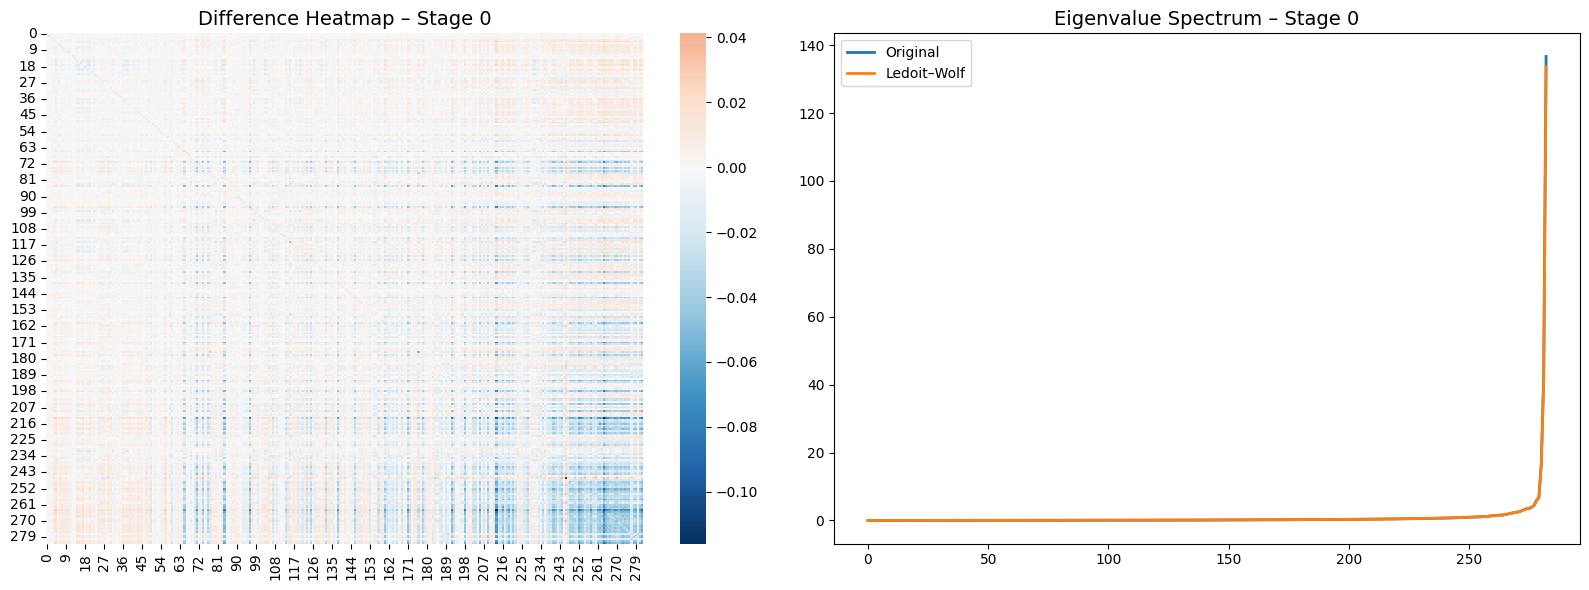

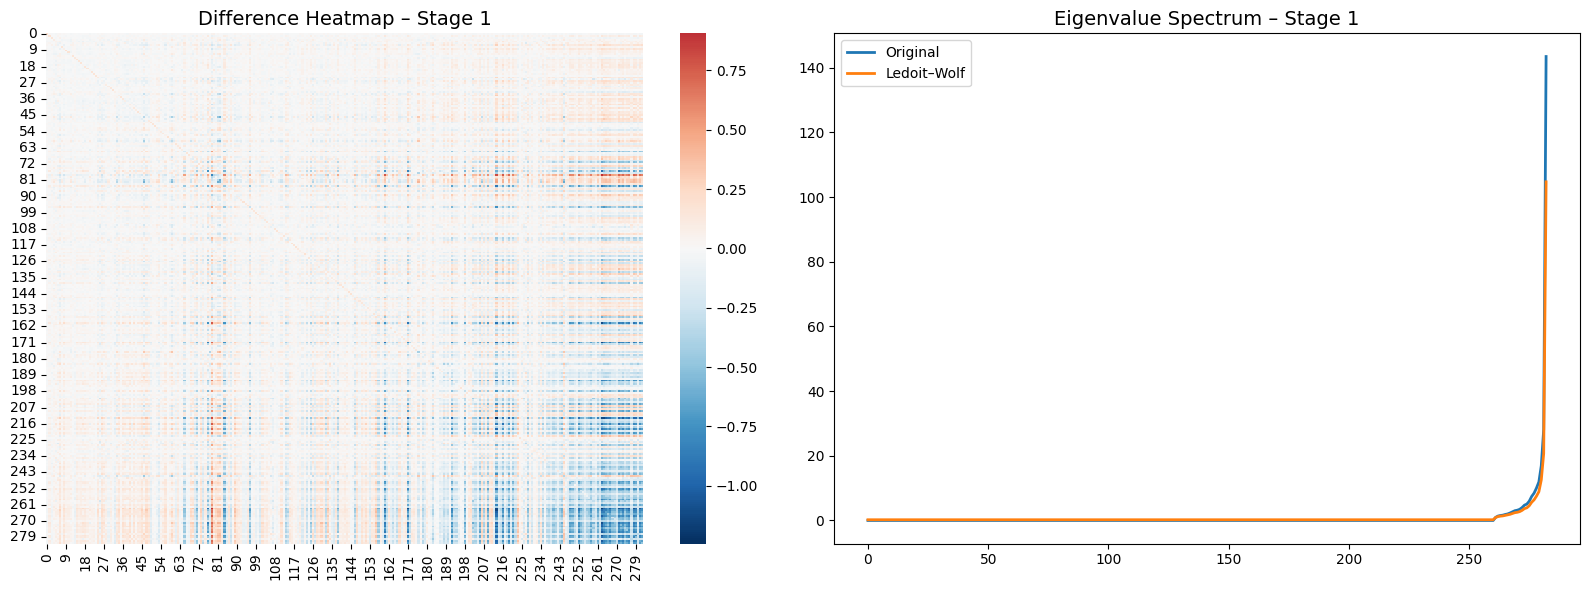

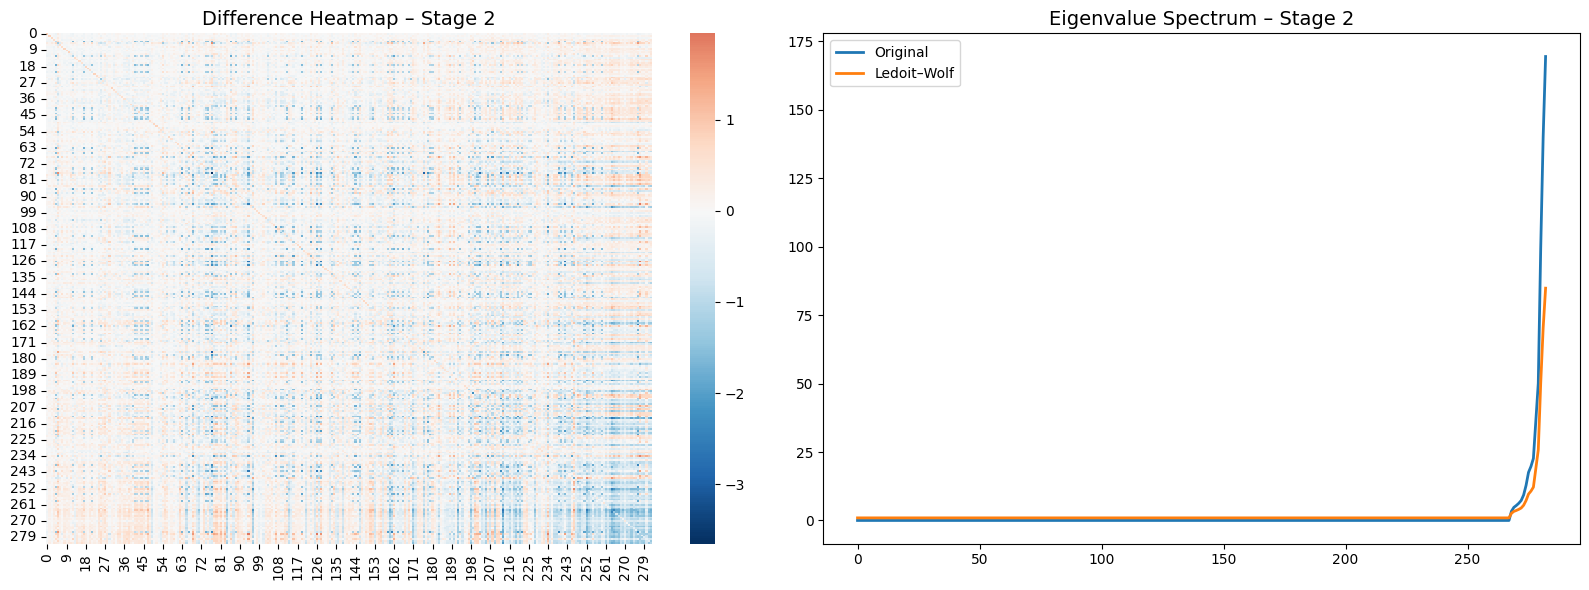

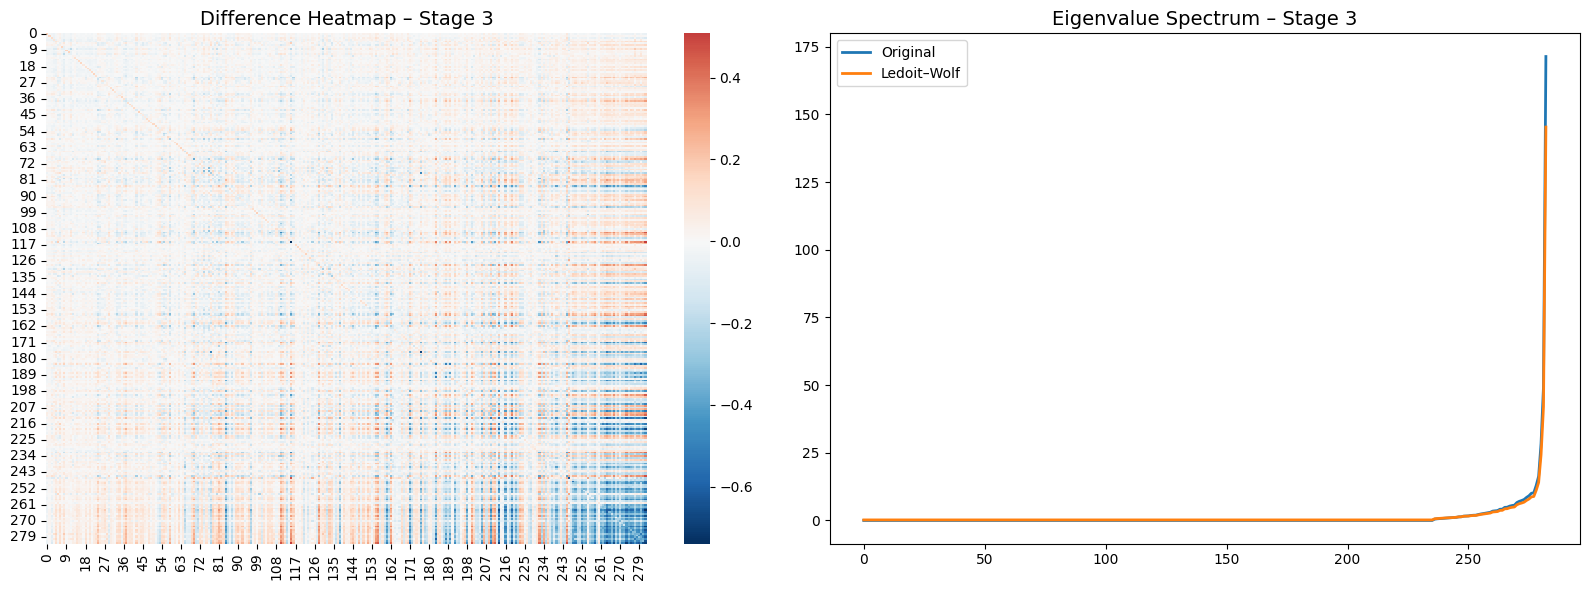

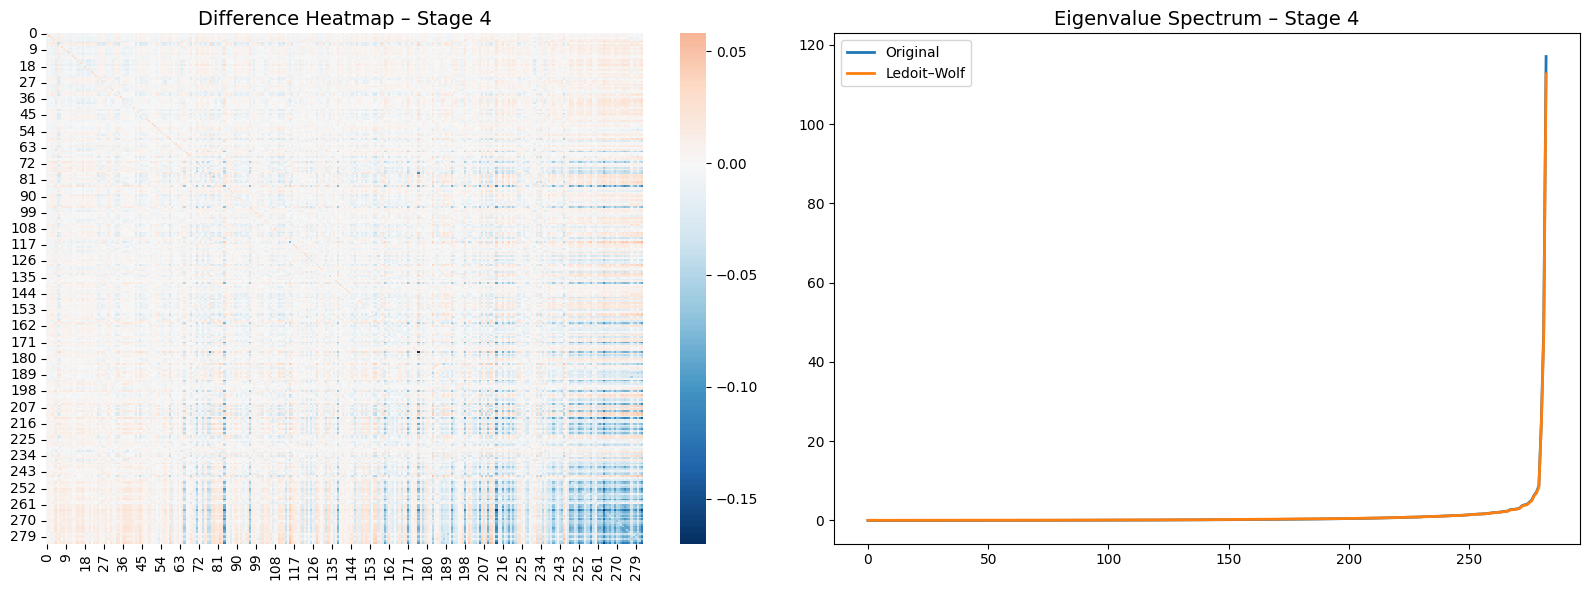

In [ ]:
for k, stage in enumerate(stage_order):

    S_file = S_hat_list_1[k]
    S_est  = S_hat_list[k]

    diff = S_est - S_file

    # Prepare eigenvalues
    eig_orig = np.linalg.eigvalsh(S_file)
    eig_est  = np.linalg.eigvalsh(S_est)

    # --- PLOT: Difference Heatmap + Eigenvalue Spectrum ---
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # 1. Difference heatmap (bigger and centered color scale)
    sns.heatmap(diff, ax=axes[0], cmap="RdBu_r", center=0)
    axes[0].set_title(f"Difference Heatmap – Stage {stage}", fontsize=14)

    # 2. Eigenvalue spectrum
    axes[1].plot(eig_orig, label="Original", linewidth=2)
    axes[1].plot(eig_est, label="Ledoit–Wolf", linewidth=2)
    axes[1].set_title(f"Eigenvalue Spectrum – Stage {stage}", fontsize=14)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    print("="*25)


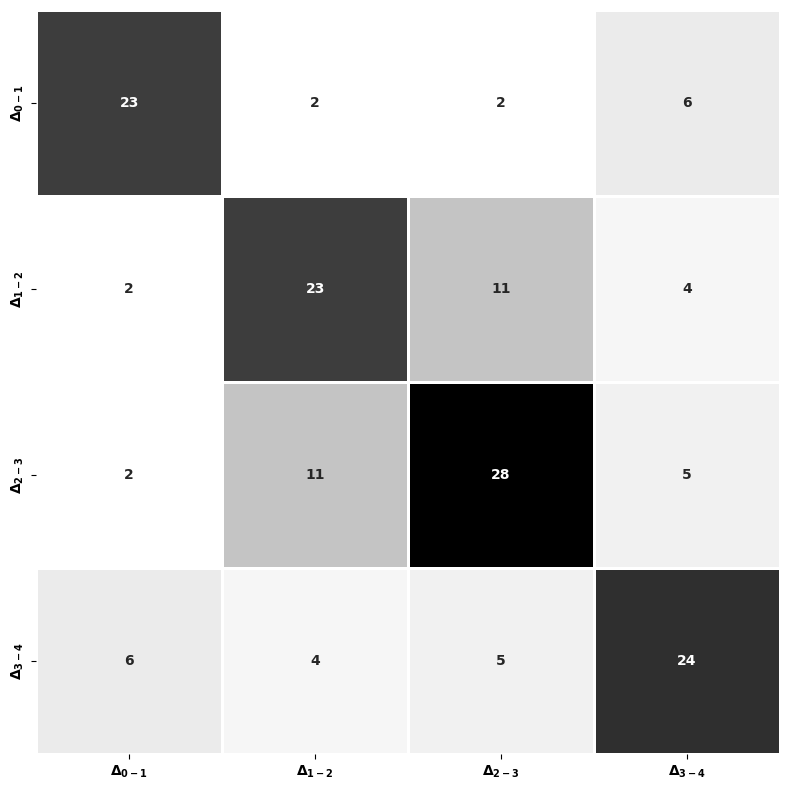

In [ ]:
# Calculate intersection sizes
n = len(specific_hubs_3)
intersection_matrix = np.zeros((n, n), dtype=int)

for i in range(n):
    for j in range(n):
        intersection_matrix[i, j] = len(
            set(specific_hubs_3[i]).intersection(specific_hubs_3[j])
        )

# Labels with bold Delta + subscripts
labels = [rf"$\mathbf{{\Delta_{{{i}-{i+1}}}}}$" for i in range(n)]

# Create heatmap
plt.figure(figsize=(8, 8))

sns.heatmap(intersection_matrix,annot=True,
    fmt='d',
    cmap='Greys',              # BEST thesis choice
    xticklabels=labels,
    yticklabels=labels,
    square=True,
    cbar=False,
    linewidths=1,
    linecolor='white',
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

plt.xlabel("", fontsize=12, fontweight='bold')
plt.ylabel("", fontsize=12, fontweight='bold')

plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')

plt.tight_layout()
plt.show()


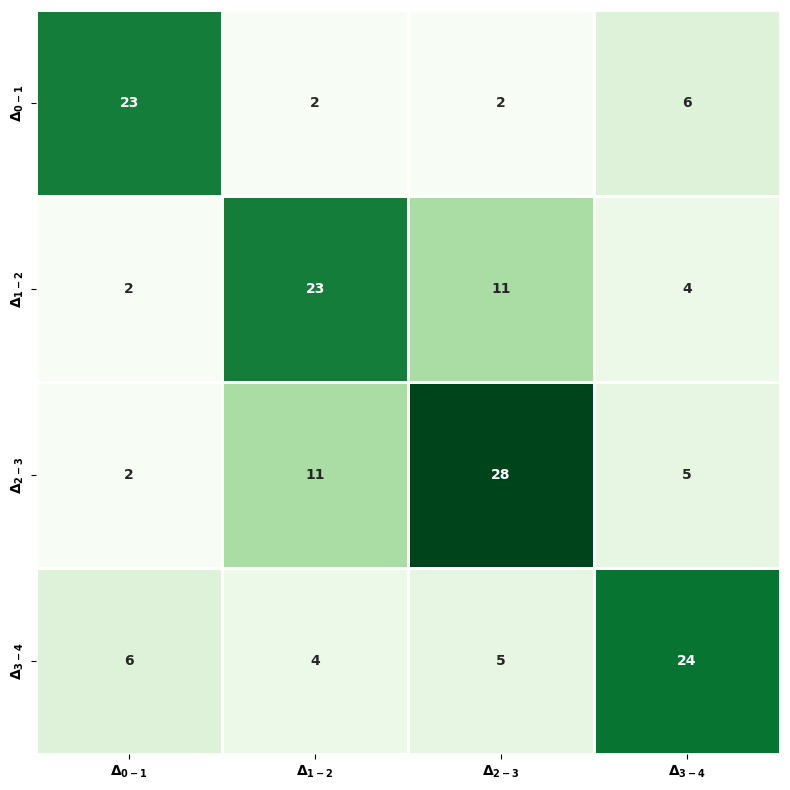

In [ ]:
# Calculate intersection sizes
n = len(specific_hubs_3)
intersection_matrix = np.zeros((n, n), dtype=int)

for i in range(n):
    for j in range(n):
        intersection_matrix[i, j] = len(
            set(specific_hubs_3[i]).intersection(specific_hubs_3[j])
        )

# Labels with bold Delta + subscripts
labels = [rf"$\mathbf{{\Delta_{{{i}-{i+1}}}}}$" for i in range(n)]

# Create heatmap
plt.figure(figsize=(8, 8))

sns.heatmap(intersection_matrix,annot=True,
    fmt='d',
    cmap='Greens',              # BEST thesis choice
    xticklabels=labels,
    yticklabels=labels,
    square=True,
    cbar=False,
    linewidths=1,
    linecolor='white',
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

plt.xlabel("", fontsize=12, fontweight='bold')
plt.ylabel("", fontsize=12, fontweight='bold')

plt.xticks(fontweight='bold')
plt.yticks(fontweight='bold')

plt.tight_layout()
plt.show()




---



### ENRICHMENT ANALYSIS

In [26]:
common_hubs_3

['ARMC3', 'ENSG00000269028']

In [27]:
#enrichr_libraries = ["GO_Biological_Process_2023","GO_Molecular_Function_2023","GO_Cellular_Component_2023",
#                     "Reactome_2022","KEGG_2021_Human","MSigDB_Hallmark_2020"]

enrichr_libraries = [
    "GO_Biological_Process_2026",
    "GO_Molecular_Function_2026",
    "GO_Cellular_Component_2026",
    "Reactome_Pathways_2024",
    "KEGG_2026",
    "MSigDB_Hallmark_2020"
]

putative_results = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(common_hubs_3, library,final_gene_list)
    putative_results[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value","Genes"]].head())
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2026:
Results for GO_Biological_Process_2026 (Putative Genes):
                                 Term  Adjusted P-value  Genes
0  Spermatid Development (GO:0007286)          0.015769  ARMC3
1         Macroautophagy (GO:0016236)          0.017622  ARMC3
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2026:
Results for GO_Molecular_Function_2026 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for GO_Cellular_Component_2026:
Results for GO_Cellular_Component_2026 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for Reactome_Pathways_2024:
Results for Reactome_Pathways_2024 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for KEGG_2026:
Results for KEGG_2026 (Putative Genes):
No significant enrichment found.
--------------------------

# PROVA OVARIAN Dataset In't Veld

In [40]:
@jit
def soft_threshold(v, lam):
    return jnp.sign(v) * jnp.maximum(jnp.abs(v) - lam, 0.0)

@jit
def altra_jax_vectorized(V_concat, ind, nodes):
    """
    Fully vectorized ALTRA implementation - processes entire matrix at once.
    """
    # Check if first node is special L1 node
    is_special_node = lax.cond(
        nodes > 0,
        lambda _: (ind[0, 0] == -1) & (ind[1, 0] == -1),
        lambda _: False,
        None
    )

    # Apply special node if needed (L1 penalty on all elements)
    def apply_special_node(x):
        lam = ind[2, 0]
        return soft_threshold(x, lam), 1

    def skip_special_node(x):
        return x, 0

    X = lax.cond(is_special_node, apply_special_node, skip_special_node, V_concat)[0]
    i0 = lax.cond(is_special_node, lambda _: 1, lambda _: 0, None)

    # Vectorized group processing
    def process_node(i, x_flat):
        start = ind[0, i].astype(int) - 1
        end = ind[1, i].astype(int)
        lam = ind[2, i]

        # Extract group
        indices = jnp.arange(x_flat.shape[0])
        mask = (indices >= start) & (indices < end)
        group = jnp.where(mask, x_flat, 0.0)

        # Group soft threshold
        norm = jnp.linalg.norm(group)
        scale = jnp.maximum(1.0 - lam / (norm + 1e-12), 0.0)
        thresholded = group * scale

        # Update
        return jnp.where(mask, thresholded, x_flat)

    # Flatten, process, reshape
    original_shape = X.shape
    X_flat = X.ravel()
    X_flat = lax.fori_loop(i0, nodes, process_node, X_flat)
    X = X_flat.reshape(original_shape)

    return X


@jit
def tree_structured_proximal_operator_fast(Y_concat, ind, nodes):
    """
    Ultra-fast proximal operator - processes entire concatenated matrix.
    No loops over columns, fully vectorized.
    """
    return altra_jax_vectorized(Y_concat, ind, nodes)


def build_index_structure(K_minus_1, p, lambda_val, omega1, omega2, omega3):
    """Build index structure (not JIT-compiled due to dynamic shape)"""
    nodes = K_minus_1 + 2
    ind = jnp.zeros((3, nodes))

    # Special L1 node
    ind = ind.at[:, 0].set(jnp.array([-1.0, -1.0, lambda_val * omega1]))

    # Stage groups (children)
    k_indices = jnp.arange(K_minus_1)
    ind = ind.at[0, 1:K_minus_1+1].set(k_indices * p + 1)
    ind = ind.at[1, 1:K_minus_1+1].set((k_indices + 1) * p)
    ind = ind.at[2, 1:K_minus_1+1].set(lambda_val * omega2)

    # Root group (parent)
    ind = ind.at[0, K_minus_1 + 1].set(1)
    ind = ind.at[1, K_minus_1 + 1].set(K_minus_1 * p)
    ind = ind.at[2, K_minus_1 + 1].set(lambda_val * omega3)

    return ind, nodes


@jit
def d_trace_loss_gradient_optimized(V_stack, S_stack, S_next_stack):
    """Fully vectorized gradient of trace loss"""
    D = V_stack + V_stack.transpose(0, 2, 1)
    term1 = jnp.einsum('kij,kjl,klm->kim', S_stack, D, S_next_stack)
    term2 = jnp.einsum('kij,kjl,klm->kim', S_next_stack, D, S_stack)
    grad = term1 + term2 - 2.0 * (S_stack - S_next_stack)
    return grad


@jit
def d_trace_loss_optimized(V_stack, S_stack, S_next_stack):
    """Fully vectorized loss computation"""
    D = V_stack + V_stack.transpose(0, 2, 1)
    SD = jnp.einsum('kij,kjl->kil', S_stack, D)
    S_next_D = jnp.einsum('kij,kjl->kil', S_next_stack, D)

    term1 = 0.25 * jnp.sum(SD * jnp.einsum('kij,kjl->kil', D, S_next_stack))
    term2 = 0.25 * jnp.sum(S_next_D * jnp.einsum('kij,kjl->kil', D, S_stack))
    term3 = jnp.sum(D * (S_stack - S_next_stack))

    return term1 + term2 - term3


@jit
def tree_norm_jax(V_stack, omega_1, omega_2, omega_3):
    """Fully vectorized tree norm computation"""
    l1_penalty = omega_1 * jnp.sum(jnp.abs(V_stack))
    col_norms = jnp.linalg.norm(V_stack, axis=1)
    l2_penalty = omega_2 * jnp.sum(col_norms)
    col_norms_per_feature = jnp.sum(V_stack ** 2, axis=1)
    col_norms_squared_total = jnp.sum(col_norms_per_feature, axis=0)
    root_penalty = omega_3 * jnp.sum(jnp.sqrt(col_norms_squared_total))
    return l1_penalty + l2_penalty + root_penalty


def proximal_gradient_step(Y_stack, grad_stack, alpha, ind, nodes, lambda_val):
    """
    Complete proximal gradient step.
    IMPORTANT: ind already contains lambda_val baked in, we need to scale by alpha!
    """
    # Gradient step
    A_stack = Y_stack - alpha * grad_stack

    # Scale penalties by alpha (they already contain lambda_val)
    ind_scaled = ind.at[2, :].multiply(alpha)

    # Reshape to concatenated form
    K_minus_1, p = Y_stack.shape[0], Y_stack.shape[1]
    A_concat = A_stack.reshape(K_minus_1 * p, p)

    # Proximal operator (fully vectorized and JIT-compiled)
    Z_concat = tree_structured_proximal_operator_fast(A_concat, ind_scaled, nodes)

    # Reshape back
    Z_stack = Z_concat.reshape(K_minus_1, p, p)

    return Z_stack


def proximal_gradient_step_debug(Y_stack, grad_stack, alpha, ind, nodes, lambda_val):
    """Debug version with detailed output"""
    A_stack = Y_stack - alpha * grad_stack

    # Scale penalties by alpha
    ind_scaled = ind.at[2, :].multiply(alpha)
    K_minus_1, p = Y_stack.shape[0], Y_stack.shape[1]
    A_concat = A_stack.reshape(K_minus_1 * p, p)
    Z_concat = tree_structured_proximal_operator_fast(A_concat, ind_scaled, nodes)
    Z_stack = Z_concat.reshape(K_minus_1, p, p)

    return Z_stack


@jit
def compute_backtracking_criterion(Y_stack, Z_stack, grad_stack, S_stack, S_next_stack, alpha):
    """Combined backtracking check - fully JIT compiled"""
    loss_Y = d_trace_loss_optimized(Y_stack, S_stack, S_next_stack)
    loss_Z = d_trace_loss_optimized(Z_stack, S_stack, S_next_stack)

    diff = Z_stack - Y_stack
    grad_diff = jnp.sum(grad_stack * diff)
    quad_term = jnp.sum(diff ** 2) / (2 * alpha)

    criterion = loss_Z - (loss_Y + grad_diff + quad_term)
    return criterion, loss_Z


def single_iteration_body(V_stack, V_old_stack, t, alpha_init, ind, nodes, lambda_val, S_stack, S_next_stack):
    """
    Single iteration of accelerated proximal gradient.
    """
    # Nesterov momentum
    m = t / (t + 3.0)
    Y_stack = V_stack + m * (V_stack - V_old_stack)

    # Gradient
    grad_stack = d_trace_loss_gradient_optimized(Y_stack, S_stack, S_next_stack)


    # Backtracking line search - start from previous successful alpha
    alpha = alpha_init
    best_alpha = alpha_init

    for backtrack_iter in range(25):
        # Proximal gradient step
        A_stack = Y_stack - alpha * grad_stack

        Z_stack = proximal_gradient_step(Y_stack, grad_stack, alpha, ind, nodes, lambda_val)


        # Check criterion
        criterion, loss_Z = compute_backtracking_criterion(Y_stack, Z_stack, grad_stack, S_stack, S_next_stack, alpha)

        if criterion <= 0:
            best_alpha = alpha
            break
        alpha *= 0.5
    else:
        # If we exhausted all iterations, use the last alpha anyway
        print(f"  Warning: Backtracking failed to converge, using alpha={alpha:.6e}")


    return Z_stack, loss_Z, best_alpha


def tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, omega1, omega2, omega3, max_iter=1000):
    """
    Ultra-optimized JAX implementation with maximum JIT compilation.
    """
    K = len(S_hat_list)
    p = S_hat_list[0].shape[0]
    K_minus_1 = K - 1

    # Convert to JAX arrays
    S_hat_stack = jnp.stack([jnp.array(S) for S in S_hat_list])
    S_stack = S_hat_stack[:-1]
    S_next_stack = S_hat_stack[1:]



    # Build index structure once
    ind, nodes = build_index_structure(K_minus_1, p, lambda_val, omega1, omega2, omega3)

    # Initialize
    V_stack = jnp.zeros((K_minus_1, p, p))
    V_old_stack = V_stack.copy()

    # Compute initial loss
    initial_loss = d_trace_loss_optimized(V_stack, S_stack, S_next_stack)

    # Try one gradient step to check
    grad_stack = d_trace_loss_gradient_optimized(V_stack, S_stack, S_next_stack)
    grad_norm = float(jnp.linalg.norm(grad_stack))



    history = {'objective': [], 'loss': [], 'penalty': []}

    # Adaptive step size - start from successful alpha from previous iteration
    alpha_init = 1.0

    for t in range(1, max_iter + 1):
        # Run one iteration
        Z_stack, loss, alpha_used = single_iteration_body(
            V_stack, V_old_stack, t,
            alpha_init, ind, nodes, lambda_val,
            S_stack, S_next_stack)

        # Update alpha_init for next iteration (warm start)
        # Start from 2x the successful alpha, but cap at 1.0
        alpha_init = min(2.0 * alpha_used, 1.0)

        # Update: old becomes current, current becomes new
        V_old_stack = V_stack
        V_stack = Z_stack



        # Compute objective
        penalty = tree_norm_jax(V_stack, omega1, omega2, omega3)
        objective = loss + lambda_val * penalty


        history['objective'].append(float(objective))
        history['loss'].append(float(loss))
        history['penalty'].append(float(penalty))

        # Convergence check
        if len(history['objective']) > 1:
            obj_change = abs(history['objective'][-1] - history['objective'][-2])
            rel_change = obj_change / (abs(history['objective'][-2]) + 1e-10)
            if rel_change <= 0.0001 and t > 2:
                break

        if (t % 20 == 0 and t < 201) or t < 11 or (t % 50 == 0 and t > 200):
            print(f"Iter {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    D_stack = V_stack + V_stack.transpose(0, 2, 1)
    print(f"\nCompleted at iteration {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    # Convert back to lists
    V_list = [np.array(V_stack[k]) for k in range(K_minus_1)]
    D_list = [np.array(D_stack[k]) for k in range(K_minus_1)]

    return V_list, D_list, history

In [41]:
data_dir = "/content"
sigma_hat_list = {}
X_list = {}
stage_order =  ["0","1", "2", "3","4"]

In [42]:
genes = pd.read_csv("genes_keep.csv")["genes"].tolist()
print(len(genes))

1228


In [43]:
X_list = []
for stage in stage_order:
  X_df = pd.read_csv(os.path.join(data_dir, f"X_{stage}.csv"), index_col=0)
  X_list.append(X_df.values)

In [44]:
[X.shape[0] for X in X_list],[X.shape[1] for X in X_list]

([216, 36, 18, 49, 35], [1228, 1228, 1228, 1228, 1228])

In [45]:
mg = mygene.MyGeneInfo()
result = convert_to_hgnc_or_keep_ensembl(genes, keep_version=True)

In [46]:
kept_as_ensg = [orig for orig, sym in result.items() if orig.startswith('ENSG') and sym.startswith('ENSG')]
if kept_as_ensg:
    print("\nThese were NOT found and kept as Ensembl IDs:")
    for g in kept_as_ensg:
        print(f"   -> {g}")

In [47]:
final_gene_list = [result[g] for g in genes]

In [48]:
S_hat_list = []
for k, X_k in enumerate(X_list):
    n_samples, p_features = X_k.shape
    lw = LedoitWolf(store_precision=False)
    lw.fit(X_k)
    S_k = lw.covariance_
    print(f"Stage {k}: n={n_samples}, p={p_features}, using shrinkage ({lw.shrinkage_:.3f})")
    S_hat_list.append(S_k)

Stage 0: n=216, p=1228, using shrinkage (0.012)
Stage 1: n=36, p=1228, using shrinkage (0.101)
Stage 2: n=18, p=1228, using shrinkage (0.252)
Stage 3: n=49, p=1228, using shrinkage (0.129)
Stage 4: n=35, p=1228, using shrinkage (0.195)


In [49]:
p= len(genes)
K = len(X_list)

nu1 = 1.0
nu2 = np.sqrt(np.log(p))
nu3 = np.sqrt(np.log(p * (K - 1)))
lambda_val= 0.92

V_list, D_list, history = tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, nu1, nu2, nu3, max_iter=1000) #

Iter 1, Loss: -1.805, Penalty: 1.646, Objective: -0.291
Iter 2, Loss: -2.681, Penalty: 2.404, Objective: -0.469
Iter 3, Loss: -3.283, Penalty: 2.874, Objective: -0.639
Iter 4, Loss: -4.085, Penalty: 3.559, Objective: -0.812
Iter 5, Loss: -4.738, Penalty: 4.117, Objective: -0.951
Iter 6, Loss: -5.372, Penalty: 4.642, Objective: -1.101
Iter 7, Loss: -6.252, Penalty: 5.399, Objective: -1.285
Iter 8, Loss: -7.696, Penalty: 6.692, Objective: -1.539
Iter 9, Loss: -9.022, Penalty: 7.893, Objective: -1.760
Iter 10, Loss: -10.360, Penalty: 9.102, Objective: -1.986
Iter 20, Loss: -27.514, Penalty: 25.344, Objective: -4.197
Iter 40, Loss: -75.977, Penalty: 73.813, Objective: -8.069
Iter 60, Loss: -141.631, Penalty: 142.480, Objective: -10.550
Iter 80, Loss: -218.490, Penalty: 226.956, Objective: -9.691
Iter 100, Loss: -299.249, Penalty: 318.878, Objective: -5.881
Iter 120, Loss: -398.964, Penalty: 437.299, Objective: 3.351
Iter 140, Loss: -493.263, Penalty: 554.168, Objective: 16.572
Iter 160, Lo

In [50]:
p_thresh=[]
for i, D in enumerate(D_list):
    stats, vals = analyze_matrix_distribution(D)
    p_thresh.append(stats['absolute percentiles'][75])

In [51]:
common_hubs_3, specific_hubs_3, hub_degrees_3 = identify_hubs_from_V2(V_list,D_list, genes=final_gene_list,threshold_percentile=90,zero_tol=p_thresh,thresh_k=True)
print_hubs_info(common_hubs_3, specific_hubs_3,hub_degrees_3,10)

---------HUBS INFO--------

Number of common hubs: 12

Number of hubs in stage 0-1: 71
Number of hubs in stage 1-2: 67
Number of hubs in stage 2-3: 69
Number of hubs in stage 3-4: 58

 Degree stage 0-1
    1. HSPA5: degree = 83  
    2. FOS: degree = 69 COMMON
    3. PRKCH: degree = 64  
    4. IL7R: degree = 53 COMMON
    5. CHST2: degree = 52 COMMON
    6. NFKB1: degree = 52  
    7. NDUFS2: degree = 47  
    8. STYX: degree = 46  
    9. SORL1: degree = 40  
    10. SND1: degree = 39  

 Degree stage 1-2
    1. HBB: degree = 50  
    2. FOS: degree = 49 COMMON
    3. HSPA5: degree = 48  
    4. PRKCH: degree = 44  
    5. CXCR2: degree = 38  
    6. CLEC2D: degree = 37  
    7. LINC02915: degree = 36 COMMON
    8. IL7R: degree = 33 COMMON
    9. CD53: degree = 32  
    10. MLC1: degree = 31  

 Degree stage 2-3
    1. HBB: degree = 48  
    2. LINC02915: degree = 42 COMMON
    3. IL7R: degree = 39 COMMON
    4. CCT5: degree = 36  
    5. SAMD9: degree = 35  
    6. FOS: degree = 34 

In [52]:
HUBS=list(set(common_hubs_3).union(set(specific_hubs_3[0])).union(set(specific_hubs_3[1])).union(set(specific_hubs_3[2]).union(set(specific_hubs_3[3]))))
len(HUBS)

185

In [53]:
#enrichr_libraries = ["GO_Biological_Process_2023","GO_Molecular_Function_2023","GO_Cellular_Component_2023",
#                     "Reactome_2022","KEGG_2021_Human","MSigDB_Hallmark_2020"]

enrichr_libraries = [
    "GO_Biological_Process_2026",
    "GO_Molecular_Function_2026",
    "GO_Cellular_Component_2026",
    "Reactome_Pathways_2024",
    "KEGG_2026",
    "MSigDB_Hallmark_2020"
]

putative_results = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(common_hubs_3, library,final_gene_list)
    putative_results[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value","Genes"]].head())
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2026:
Results for GO_Biological_Process_2026 (Putative Genes):
                                                Term  Adjusted P-value  Genes
0  Negative Regulation of Fas Signaling Pathway (...          0.041117   IL7R
1  Negative Regulation of Tyrosine Phosphorylatio...          0.041117   IL7R
2  Positive Regulation of Leukocyte Tethering or ...          0.041117  CHST2
3   Regulation of Fas Signaling Pathway (GO:1902044)          0.041117   IL7R
4    Cellular Response to Interleukin-7 (GO:0098761)          0.041117   IL7R
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2026:
Results for GO_Molecular_Function_2026 (Putative Genes):
                                                Term  Adjusted P-value  Genes
0  MAP Kinase Tyrosine Phosphatase Activity (GO:0...          0.024752  DUSP6
1  MAP Kinase Tyrosine/Serine/Threonine Phosphata...          0.024752  DUSP6
2  N-acetylglucosamine 6-O-sulfotransfera

# PROVA CRC Xu's Dataset

In [54]:
@jit
def soft_threshold(v, lam):
    return jnp.sign(v) * jnp.maximum(jnp.abs(v) - lam, 0.0)

@jit
def altra_jax_vectorized(V_concat, ind, nodes):
    """
    Fully vectorized ALTRA implementation - processes entire matrix at once.
    """
    # Check if first node is special L1 node
    is_special_node = lax.cond(
        nodes > 0,
        lambda _: (ind[0, 0] == -1) & (ind[1, 0] == -1),
        lambda _: False,
        None
    )

    # Apply special node if needed (L1 penalty on all elements)
    def apply_special_node(x):
        lam = ind[2, 0]
        return soft_threshold(x, lam), 1

    def skip_special_node(x):
        return x, 0

    X = lax.cond(is_special_node, apply_special_node, skip_special_node, V_concat)[0]
    i0 = lax.cond(is_special_node, lambda _: 1, lambda _: 0, None)

    # Vectorized group processing
    def process_node(i, x_flat):
        start = ind[0, i].astype(int) - 1
        end = ind[1, i].astype(int)
        lam = ind[2, i]

        # Extract group
        indices = jnp.arange(x_flat.shape[0])
        mask = (indices >= start) & (indices < end)
        group = jnp.where(mask, x_flat, 0.0)

        # Group soft threshold
        norm = jnp.linalg.norm(group)
        scale = jnp.maximum(1.0 - lam / (norm + 1e-12), 0.0)
        thresholded = group * scale

        # Update
        return jnp.where(mask, thresholded, x_flat)

    # Flatten, process, reshape
    original_shape = X.shape
    X_flat = X.ravel()
    X_flat = lax.fori_loop(i0, nodes, process_node, X_flat)
    X = X_flat.reshape(original_shape)

    return X


@jit
def tree_structured_proximal_operator_fast(Y_concat, ind, nodes):
    """
    Ultra-fast proximal operator - processes entire concatenated matrix.
    No loops over columns, fully vectorized.
    """
    return altra_jax_vectorized(Y_concat, ind, nodes)


def build_index_structure(K_minus_1, p, lambda_val, omega1, omega2, omega3):
    """Build index structure (not JIT-compiled due to dynamic shape)"""
    nodes = K_minus_1 + 2
    ind = jnp.zeros((3, nodes))

    # Special L1 node
    ind = ind.at[:, 0].set(jnp.array([-1.0, -1.0, lambda_val * omega1]))

    # Stage groups (children)
    k_indices = jnp.arange(K_minus_1)
    ind = ind.at[0, 1:K_minus_1+1].set(k_indices * p + 1)
    ind = ind.at[1, 1:K_minus_1+1].set((k_indices + 1) * p)
    ind = ind.at[2, 1:K_minus_1+1].set(lambda_val * omega2)

    # Root group (parent)
    ind = ind.at[0, K_minus_1 + 1].set(1)
    ind = ind.at[1, K_minus_1 + 1].set(K_minus_1 * p)
    ind = ind.at[2, K_minus_1 + 1].set(lambda_val * omega3)

    return ind, nodes


@jit
def d_trace_loss_gradient_optimized(V_stack, S_stack, S_next_stack):
    """Fully vectorized gradient of trace loss"""
    D = V_stack + V_stack.transpose(0, 2, 1)
    term1 = jnp.einsum('kij,kjl,klm->kim', S_stack, D, S_next_stack)
    term2 = jnp.einsum('kij,kjl,klm->kim', S_next_stack, D, S_stack)
    grad = term1 + term2 - 2.0 * (S_stack - S_next_stack)
    return grad


@jit
def d_trace_loss_optimized(V_stack, S_stack, S_next_stack):
    """Fully vectorized loss computation"""
    D = V_stack + V_stack.transpose(0, 2, 1)
    SD = jnp.einsum('kij,kjl->kil', S_stack, D)
    S_next_D = jnp.einsum('kij,kjl->kil', S_next_stack, D)

    term1 = 0.25 * jnp.sum(SD * jnp.einsum('kij,kjl->kil', D, S_next_stack))
    term2 = 0.25 * jnp.sum(S_next_D * jnp.einsum('kij,kjl->kil', D, S_stack))
    term3 = jnp.sum(D * (S_stack - S_next_stack))

    return term1 + term2 - term3


@jit
def tree_norm_jax(V_stack, omega_1, omega_2, omega_3):
    """Fully vectorized tree norm computation"""
    l1_penalty = omega_1 * jnp.sum(jnp.abs(V_stack))
    col_norms = jnp.linalg.norm(V_stack, axis=1)
    l2_penalty = omega_2 * jnp.sum(col_norms)
    col_norms_per_feature = jnp.sum(V_stack ** 2, axis=1)
    col_norms_squared_total = jnp.sum(col_norms_per_feature, axis=0)
    root_penalty = omega_3 * jnp.sum(jnp.sqrt(col_norms_squared_total))
    return l1_penalty + l2_penalty + root_penalty


def proximal_gradient_step(Y_stack, grad_stack, alpha, ind, nodes, lambda_val):
    """
    Complete proximal gradient step.
    IMPORTANT: ind already contains lambda_val baked in, we need to scale by alpha!
    """
    # Gradient step
    A_stack = Y_stack - alpha * grad_stack

    # Scale penalties by alpha (they already contain lambda_val)
    ind_scaled = ind.at[2, :].multiply(alpha)

    # Reshape to concatenated form
    K_minus_1, p = Y_stack.shape[0], Y_stack.shape[1]
    A_concat = A_stack.reshape(K_minus_1 * p, p)

    # Proximal operator (fully vectorized and JIT-compiled)
    Z_concat = tree_structured_proximal_operator_fast(A_concat, ind_scaled, nodes)

    # Reshape back
    Z_stack = Z_concat.reshape(K_minus_1, p, p)

    return Z_stack


def proximal_gradient_step_debug(Y_stack, grad_stack, alpha, ind, nodes, lambda_val):
    """Debug version with detailed output"""
    A_stack = Y_stack - alpha * grad_stack

    # Scale penalties by alpha
    ind_scaled = ind.at[2, :].multiply(alpha)
    K_minus_1, p = Y_stack.shape[0], Y_stack.shape[1]
    A_concat = A_stack.reshape(K_minus_1 * p, p)
    Z_concat = tree_structured_proximal_operator_fast(A_concat, ind_scaled, nodes)
    Z_stack = Z_concat.reshape(K_minus_1, p, p)

    return Z_stack


@jit
def compute_backtracking_criterion(Y_stack, Z_stack, grad_stack, S_stack, S_next_stack, alpha):
    """Combined backtracking check - fully JIT compiled"""
    loss_Y = d_trace_loss_optimized(Y_stack, S_stack, S_next_stack)
    loss_Z = d_trace_loss_optimized(Z_stack, S_stack, S_next_stack)

    diff = Z_stack - Y_stack
    grad_diff = jnp.sum(grad_stack * diff)
    quad_term = jnp.sum(diff ** 2) / (2 * alpha)

    criterion = loss_Z - (loss_Y + grad_diff + quad_term)
    return criterion, loss_Z


def single_iteration_body(V_stack, V_old_stack, t, alpha_init, ind, nodes, lambda_val, S_stack, S_next_stack):
    """
    Single iteration of accelerated proximal gradient.
    """
    # Nesterov momentum
    m = t / (t + 3.0)
    Y_stack = V_stack + m * (V_stack - V_old_stack)

    # Gradient
    grad_stack = d_trace_loss_gradient_optimized(Y_stack, S_stack, S_next_stack)


    # Backtracking line search - start from previous successful alpha
    alpha = alpha_init
    best_alpha = alpha_init

    for backtrack_iter in range(25):
        # Proximal gradient step
        A_stack = Y_stack - alpha * grad_stack

        Z_stack = proximal_gradient_step(Y_stack, grad_stack, alpha, ind, nodes, lambda_val)


        # Check criterion
        criterion, loss_Z = compute_backtracking_criterion(Y_stack, Z_stack, grad_stack, S_stack, S_next_stack, alpha)

        if criterion <= 0:
            best_alpha = alpha
            break
        alpha *= 0.5
    else:
        # If we exhausted all iterations, use the last alpha anyway
        print(f"  Warning: Backtracking failed to converge, using alpha={alpha:.6e}")


    return Z_stack, loss_Z, best_alpha


def tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, omega1, omega2, omega3, max_iter=1000):
    """
    Ultra-optimized JAX implementation with maximum JIT compilation.
    """
    K = len(S_hat_list)
    p = S_hat_list[0].shape[0]
    K_minus_1 = K - 1

    # Convert to JAX arrays
    S_hat_stack = jnp.stack([jnp.array(S) for S in S_hat_list])
    S_stack = S_hat_stack[:-1]
    S_next_stack = S_hat_stack[1:]



    # Build index structure once
    ind, nodes = build_index_structure(K_minus_1, p, lambda_val, omega1, omega2, omega3)

    # Initialize
    V_stack = jnp.zeros((K_minus_1, p, p))
    V_old_stack = V_stack.copy()

    # Compute initial loss
    initial_loss = d_trace_loss_optimized(V_stack, S_stack, S_next_stack)

    # Try one gradient step to check
    grad_stack = d_trace_loss_gradient_optimized(V_stack, S_stack, S_next_stack)
    grad_norm = float(jnp.linalg.norm(grad_stack))



    history = {'objective': [], 'loss': [], 'penalty': []}

    # Adaptive step size - start from successful alpha from previous iteration
    alpha_init = 1.0

    for t in range(1, max_iter + 1):
        # Run one iteration
        Z_stack, loss, alpha_used = single_iteration_body(
            V_stack, V_old_stack, t,
            alpha_init, ind, nodes, lambda_val,
            S_stack, S_next_stack)

        # Update alpha_init for next iteration (warm start)
        # Start from 2x the successful alpha, but cap at 1.0
        alpha_init = min(2.0 * alpha_used, 1.0)

        # Update: old becomes current, current becomes new
        V_old_stack = V_stack
        V_stack = Z_stack



        # Compute objective
        penalty = tree_norm_jax(V_stack, omega1, omega2, omega3)
        objective = loss + lambda_val * penalty


        history['objective'].append(float(objective))
        history['loss'].append(float(loss))
        history['penalty'].append(float(penalty))

        # Convergence check
        if len(history['objective']) > 1:
            obj_change = abs(history['objective'][-1] - history['objective'][-2])
            rel_change = obj_change / (abs(history['objective'][-2]) + 1e-10)
            if rel_change <= 0.0001 and t > 2:
                break

        if (t % 20 == 0 and t < 201) or t < 11 or (t % 50 == 0 and t > 200):
            print(f"Iter {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    D_stack = V_stack + V_stack.transpose(0, 2, 1)
    print(f"\nCompleted at iteration {t}, Loss: {loss:.3f}, Penalty: {penalty:.3f}, Objective: {objective:.3f}")

    # Convert back to lists
    V_list = [np.array(V_stack[k]) for k in range(K_minus_1)]
    D_list = [np.array(D_stack[k]) for k in range(K_minus_1)]

    return V_list, D_list, history

In [55]:
def ledoit_wolf_covariance(X):
    lw = LedoitWolf(store_precision=False)
    lw.fit(X)
    return lw.covariance_


def subsample_covariance_matrices(X_list,subsample_fraction = 0.8,random_state=123):
    """
    For each stage draw a random subsample of the *original* samples
    and return the corresponding Ledoit-Wolf covariances.
    """
    np.random.seed(random_state)

    S_sub_list = []
    for X_k in X_list:
        n_k = X_k.shape[0]
        sub_n = max(2, int(subsample_fraction * n_k))
        sub_n = min(sub_n, n_k)                     # never exceed available samples
        idx = np.random.choice(n_k, size=sub_n, replace=False)
        S_sub_list.append(ledoit_wolf_covariance(X_k[idx]))
    return S_sub_list


def stars_tuning_selection(X_list, lambda_grid, omega1, omega2, omega3,
                           n_subsamples=20, subsample_fraction=0.8,
                           beta_threshold=0.05, max_iter=1000,random_state=123):

    K = len(X_list)
    p = X_list[0].shape[1]

    stability_scores = []
    edge_stability = {}

    # Iterate over lambda values
    for lambda_idx, lambda_val in enumerate(lambda_grid):

        print(f"\nTesting lambda = {lambda_val:.4f} ({lambda_idx+1}/{len(lambda_grid)})")

        # Store edge selection frequency across subsamples
        # frequency matrices for the current lamda
        theta_bar = [np.zeros((p, p)) for _ in range(K - 1)]

        for s in range(n_subsamples):
            if (s + 1) % 5 == 0:
                print(f"  Subsample {s+1}/{n_subsamples}...", end='\r')

            # Generate subsampled covariance matrices
            unique_seed = random_state + s
            S_sub = subsample_covariance_matrices(X_list, subsample_fraction,unique_seed)

            V_list_sub, D_list_sub, _ = tdna_accelerated_proximal_gradient(S_sub,
                lambda_val, omega1, omega2, omega3,max_iter=max_iter)

            # Update edge selection frequency
            for k in range(K - 1):
                edge_selected = (np.abs(D_list_sub[k]) > 1e-10).astype(float)
                theta_bar[k] += edge_selected


        # Average over subsamples
        for k in range(K - 1):
            theta_bar[k] /= n_subsamples

        # Compute stability score (Equation in Step 2 of Algorithm 2)
        stab = 0.0
        for k in range(K - 1):
            # Only consider upper triangle (i < j)
            upper_tri_indices = np.triu_indices(p, k=1)
            theta_k = theta_bar[k][upper_tri_indices]
            stab += np.sum(theta_k * (1 - theta_k))

        stab = stab / ((K - 1) * (p * (p - 1) / 2))
        stability_scores.append(stab)
        edge_stability[lambda_val] = theta_bar


        print(f"\n  Stability score: {stab:.6f}")

    # Select lambda according to StARS criterion
    # λ_StARS = argmin_{λ: max_λ'≤λ Stab[λ'] ≤ β}
    lambda_stars = None
    max_instability_so_far = 0.0
    best_idx = -1

    for i, lambda_val in enumerate(lambda_grid):
        current_instability = stability_scores[i]
        max_instability_so_far = max(max_instability_so_far, current_instability)

        if max_instability_so_far <= beta_threshold:
            lambda_stars = lambda_val
            best_idx = i
        else:
            # Once max instability exceeds β, stop
            break

    # If no lambda satisfied (even first one too unstable), fall back
    if lambda_stars is None:
        print(f"StARS: No λ satisfied β ≤ {beta_threshold}. Using most stable λ.")
        best_idx = np.argmin(stability_scores)
        lambda_stars = lambda_grid[best_idx]

    stab_selected = stability_scores[best_idx]
    print(f"Selected lambda (StARS): {lambda_stars:.4f}")
    print(f"Stability score at selection: {stab_selected:.6f}")
    print(f"Max instability up to selected λ: {max(stability_scores[:best_idx+1]):.6f}")

    results_df = pd.DataFrame({'lambda': lambda_grid,'stability': stability_scores})

    return lambda_stars, results_df, edge_stability

### PREPARING DATA

In [56]:
data_dir = "/content"
sigma_hat_list = {}
X_list = {}
stage_order =  ["0","1", "2", "3"]

In [57]:
X_list = []
for stage in stage_order:
  X_df = pd.read_csv(os.path.join(data_dir, f"X_{stage}.csv"), index_col=0)
  X_list.append(X_df.values)

In [58]:
[X.shape[0] for X in X_list],[X.shape[1] for X in X_list]

([21, 25, 48, 58], [1312, 1312, 1312, 1312])

In [59]:
genes = pd.read_csv("genes_keep.csv")["genes"].tolist()
len(genes)

1312

In [60]:
mg = mygene.MyGeneInfo()
result = convert_to_hgnc_or_keep_ensembl(genes, keep_version=True)

INFO:biothings.client:querying 1-226 ...
INFO:biothings.client:Finished.
INFO:biothings.client:Pass "returnall=True" to return complete lists of duplicate or missing query terms.


In [61]:
kept_as_ensg = [orig for orig, sym in result.items() if orig.startswith('ENSG') and sym.startswith('ENSG')]
len(kept_as_ensg)

138

In [62]:
i=0
while i<len(kept_as_ensg):
  if i+10<len(kept_as_ensg):
    print(*kept_as_ensg[i:i+10])
  else:
    print(*kept_as_ensg[i:])
  i=i+10

ENSG00000223911 ENSG00000248373 ENSG00000253197 ENSG00000269215 ENSG00000259201 ENSG00000266002 ENSG00000273275 ENSG00000261872 ENSG00000272742 ENSG00000229313
ENSG00000224643 ENSG00000238221 ENSG00000236338 ENSG00000253356 ENSG00000245482 ENSG00000268583 ENSG00000261684 ENSG00000272367 ENSG00000213002 ENSG00000270823
ENSG00000260855 ENSG00000272849 ENSG00000271554 ENSG00000240571 ENSG00000212999 ENSG00000270055 ENSG00000248664 ENSG00000272600 ENSG00000253347 ENSG00000226605
ENSG00000236031 ENSG00000253358 ENSG00000269987 ENSG00000255108 ENSG00000112096 ENSG00000269832 ENSG00000197775 ENSG00000272770 ENSG00000229044 ENSG00000234117
ENSG00000259113 ENSG00000258646 ENSG00000267459 ENSG00000259071 ENSG00000226647 ENSG00000267957 ENSG00000260934 ENSG00000258449 ENSG00000259185 ENSG00000232941
ENSG00000254928 ENSG00000226252 ENSG00000258745 ENSG00000260304 ENSG00000267776 ENSG00000267359 ENSG00000259709 ENSG00000268309 ENSG00000262413 ENSG00000268800
ENSG00000240401 ENSG00000258177 ENSG0000

In [63]:
result['ENSG00000223911']='AC009480.3'
result['ENSG00000253197']='CTD-3239E11.2'
result['ENSG00000269215']='AC008964.1'
result['ENSG00000266002']='RP11-567L7.5'
result['ENSG00000238221']='RP11-69L16.4'
result['ENSG00000268583']='CTC-453G23.8'
result['ENSG00000212999']='AC117834.1'
result['ENSG00000248664']='CTC-498J12.3'
result['ENSG00000272600']='AC007308.7'
result['ENSG00000112096']='SOD2'
result['ENSG00000229044']='RP11-266K22.2'
result['ENSG00000234117']='RP11-259P20.1'
result['ENSG00000226647']='RP11-336A10.2'
result['ENSG00000232941']='AC090186.1'
result['ENSG00000258745']='RP11-218E20.5'
result['ENSG00000260304']='RP11-388M20.6'
result['ENSG00000262413']='RP11-498C9.3'
result['ENSG00000263424']='CTD-2541J13.2'
result['ENSG00000223374']='AC005104.3'
result['ENSG00000259627']='RP11-244F12.2'
result['ENSG00000243305']='RP11-362A9.3'
result['ENSG00000258232']='RP11-161H23.5'
result['ENSG00000248223']='CTD-2139B15.2'
result['ENSG00000257764']='RP11-1143G9.4'
result['ENSG00000225205']='ITGA6-AS1'
result['ENSG00000228509']='AC006460.2'
result['ENSG00000266049']='RP11-703M24.5'
result['ENSG00000259407']='RP11-158M2.3'
result['ENSG00000265401']='RP11-138I1.4'
result['ENSG00000234136']='AC055764.1'
result['ENSG00000234055']='RP11-247A12.1'
result['ENSG00000262211']='CTD-2031P19.5'
result['ENSG00000236540']='AC006547.13'
result['ENSG00000268313']='AC119673.1'
result['ENSG00000254721']='RP11-805J14.5'
result['ENSG00000227627']='RP1-101K10.6'

In [64]:
final_gene_list = [result[g] for g in genes]

In [65]:
S_hat_list = []
for k, X_k in enumerate(X_list):
    n_samples, p_features = X_k.shape
    lw = LedoitWolf(store_precision=False)
    lw.fit(X_k)
    S_k = lw.covariance_
    print(f"Stage {k}: n={n_samples}, p={p_features}, using shrinkage ({lw.shrinkage_:.3f})")
    S_hat_list.append(S_k)

Stage 0: n=21, p=1312, using shrinkage (0.158)
Stage 1: n=25, p=1312, using shrinkage (0.264)
Stage 2: n=48, p=1312, using shrinkage (0.281)
Stage 3: n=58, p=1312, using shrinkage (0.253)


In [66]:
p=len(genes)
K=len(S_hat_list)
nu1 = 1.0
nu2 = np.sqrt(np.log(p))
nu3 = np.sqrt(np.log(p * (K - 1)))
lambda_val = 1.49

V_list, D_list, history = tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, nu1, nu2, nu3, max_iter=1000) #89

Iter 1, Loss: -2.471, Penalty: 1.454, Objective: -0.305
Iter 2, Loss: -3.792, Penalty: 2.095, Objective: -0.670
Iter 3, Loss: -4.785, Penalty: 2.519, Objective: -1.032
Iter 4, Loss: -6.188, Penalty: 3.167, Objective: -1.469
Iter 5, Loss: -8.739, Penalty: 4.454, Objective: -2.102
Iter 6, Loss: -11.965, Penalty: 6.198, Objective: -2.730
Iter 7, Loss: -14.664, Penalty: 7.633, Objective: -3.291
Iter 8, Loss: -16.894, Penalty: 8.765, Objective: -3.835
Iter 9, Loss: -19.390, Penalty: 10.045, Objective: -4.423
Iter 10, Loss: -21.789, Penalty: 11.287, Objective: -4.972
Iter 20, Loss: -52.551, Penalty: 27.885, Objective: -11.003
Iter 40, Loss: -136.805, Penalty: 75.952, Objective: -23.637
Iter 60, Loss: -247.620, Penalty: 142.812, Objective: -34.831
Iter 80, Loss: -373.643, Penalty: 223.364, Objective: -40.830

Completed at iteration 89, Loss: -431.643, Penalty: 261.932, Objective: -41.364


In [67]:
p_thresh=[]
for i, D in enumerate(D_list):
    stats, vals = analyze_matrix_distribution(D)
    p_thresh.append(stats['absolute percentiles'][75])

In [68]:
common_hubs_3, specific_hubs_3, hub_degrees_3 = identify_hubs_from_V2(V_list,D_list, genes=final_gene_list,threshold_percentile=90,zero_tol=p_thresh,thresh_k=True)
print_hubs_info(common_hubs_3, specific_hubs_3,hub_degrees_3,10)

---------HUBS INFO--------

Number of common hubs: 12

Number of hubs in stage 0-1: 101
Number of hubs in stage 1-2: 81
Number of hubs in stage 2-3: 80

 Degree stage 0-1
    1. RN7SL5P: degree = 424 COMMON
    2. HOOK2: degree = 349  
    3. ADORA2A-AS1: degree = 338 COMMON
    4. CARD19: degree = 319  
    5. LINC01011: degree = 316  
    6. NQO2-AS1: degree = 316 COMMON
    7. DDX19A-DT: degree = 304  
    8. TPM1: degree = 303  
    9. F2R: degree = 285  
    10. TAGAP-AS1: degree = 271  

 Degree stage 1-2
    1. RN7SL5P: degree = 222 COMMON
    2. PLEKHA8P1: degree = 180 COMMON
    3. TPM1: degree = 172  
    4. NT5M: degree = 136  
    5. SNX24: degree = 128  
    6. SAV1: degree = 121  
    7. CHD1L: degree = 115  
    8. WIPI1: degree = 111 COMMON
    9. PROS1: degree = 110 COMMON
    10. ACER3-AS1: degree = 108  

 Degree stage 2-3
    1. RN7SL5P: degree = 123 COMMON
    2. BACH1: degree = 107  
    3. CD44-AS1: degree = 105  
    4. ADORA2A-AS1: degree = 95 COMMON
    5. THA

In [69]:
print(*common_hubs_3)

NQO2-AS1 H4C8 SUMO3 P2RY12 PROS1 ENSG00000236326 RN7SL5P PLEKHA8P1 WIPI1 EFCAB13-DT SLC45A4 ADORA2A-AS1


### enrichment

In [70]:
HUBS=list(set(common_hubs_3).union(set(specific_hubs_3[0])).union(set(specific_hubs_3[1])).union(set(specific_hubs_3[2])))
len(HUBS)

220

In [71]:
#enrichr_libraries = ["GO_Biological_Process_2023","GO_Molecular_Function_2023","GO_Cellular_Component_2023",
#                     "Reactome_2022","KEGG_2021_Human","MSigDB_Hallmark_2020"]

enrichr_libraries = [
    "GO_Biological_Process_2026",
    "GO_Molecular_Function_2026",
    "GO_Cellular_Component_2026",
    "Reactome_Pathways_2024",
    "KEGG_2026",
    "MSigDB_Hallmark_2020"
]

putative_results = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(common_hubs_3, library,final_gene_list)
    putative_results[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value","Genes"]].head())
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2026:
Results for GO_Biological_Process_2026 (Putative Genes):
                                                Term  Adjusted P-value   Genes
0    Regulation of Glial Cell Migration (GO:1903975)          0.035504  P2RY12
1  Cerebral Cortex Radial Glia-Guided Migration (...          0.035504  P2RY12
2  Positive Regulation of Microglial Cell Migrati...          0.035504  P2RY12
3  Substrate-dependent Cell Migration, Cell Exten...          0.035504  P2RY12
4                            Hemostasis (GO:0007599)          0.035504  P2RY12
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2026:
Results for GO_Molecular_Function_2026 (Putative Genes):
                                                Term  Adjusted P-value  \
0  Spermidine Transmembrane Transporter Activity ...          0.035911   
1  Carbohydrate:proton Symporter Activity (GO:000...          0.035911   
2  G Protein-Coupled Purinergic Nucleotide Rece

# PROVA GLIOBLASTOMA dataset Sol

In [72]:
data_dir = "/content"
sigma_hat_list = {}
X_list = {}
stage_order =  ["0","1", "2", "3"]

In [73]:
genes = pd.read_csv("genes_keep.csv")["genes"].tolist()
print(len(genes))

2381


In [74]:
mg = mygene.MyGeneInfo()
result = convert_to_hgnc_or_keep_ensembl(genes, keep_version=True)

In [75]:
final_gene_list = [result[g] for g in genes]

In [76]:
X_list = []
for stage in stage_order:
  X_df = pd.read_csv(os.path.join(data_dir, f"X_{stage}.csv"), index_col=0)
  X_list.append(X_df.values)

In [77]:
[X.shape[0] for X in X_list],[X.shape[1] for X in X_list]

([13, 13, 13, 13], [2381, 2381, 2381, 2381])

In [78]:
S_hat_list = []
for k, X_k in enumerate(X_list):
    n_samples, p_features = X_k.shape
    lw = LedoitWolf(store_precision=False)
    lw.fit(X_k)
    S_k = lw.covariance_
    print(f"Stage {k}: n={n_samples}, p={p_features}, using shrinkage ({lw.shrinkage_:.3f})")
    S_hat_list.append(S_k)

Stage 0: n=13, p=2381, using shrinkage (0.386)
Stage 1: n=13, p=2381, using shrinkage (0.456)
Stage 2: n=13, p=2381, using shrinkage (0.496)
Stage 3: n=13, p=2381, using shrinkage (0.398)


### ANALYZING RESULTS

In [79]:
p= len(genes)
K = len(X_list)

nu1 = 1.0
nu2 = np.sqrt(np.log(p))
nu3 = np.sqrt(np.log(p * (K - 1)))
lambda_val= 1.27

V_list, D_list, history = tdna_accelerated_proximal_gradient(S_hat_list, lambda_val, nu1, nu2, nu3, max_iter=1000) #791 iterations

Iter 1, Loss: -3.438, Penalty: 2.146, Objective: -0.713
Iter 2, Loss: -5.802, Penalty: 3.547, Objective: -1.297
Iter 3, Loss: -7.979, Penalty: 4.816, Objective: -1.863
Iter 4, Loss: -10.304, Penalty: 6.219, Objective: -2.405
Iter 5, Loss: -13.696, Penalty: 8.358, Objective: -3.081
Iter 6, Loss: -17.908, Penalty: 11.094, Objective: -3.819
Iter 7, Loss: -21.829, Penalty: 13.604, Objective: -4.552
Iter 8, Loss: -25.434, Penalty: 15.893, Objective: -5.250
Iter 9, Loss: -29.870, Penalty: 18.811, Objective: -5.981
Iter 10, Loss: -34.265, Penalty: 21.705, Objective: -6.699
Iter 20, Loss: -104.833, Penalty: 69.552, Objective: -16.501
Iter 40, Loss: -381.392, Penalty: 270.575, Objective: -37.762
Iter 60, Loss: -651.213, Penalty: 487.576, Objective: -31.991
Iter 80, Loss: -948.100, Penalty: 751.323, Objective: 6.080
Iter 100, Loss: -1185.706, Penalty: 984.890, Objective: 65.104
Iter 120, Loss: -1372.109, Penalty: 1184.605, Objective: 132.339
Iter 140, Loss: -1517.087, Penalty: 1355.209, Objectiv

In [80]:
p_thresh=[]
for i, D in enumerate(D_list):
    stats, vals = analyze_matrix_distribution(D)
    p_thresh.append(stats['absolute percentiles'][75])

In [81]:
common_hubs_3, specific_hubs_3, hub_degrees_3 = identify_hubs_from_V2(V_list,D_list, genes=final_gene_list,threshold_percentile=90,zero_tol=p_thresh,thresh_k=True)
print_hubs_info(common_hubs_3, specific_hubs_3,hub_degrees_3,10)

---------HUBS INFO--------

Number of common hubs: 11

Number of hubs in stage 0-1: 130
Number of hubs in stage 1-2: 73
Number of hubs in stage 2-3: 60

 Degree stage 0-1
    1. ME1: degree = 16  
    2. PALM2AKAP2: degree = 16 COMMON
    3. SF3B3: degree = 14  
    4. CD22: degree = 14  
    5. GPR155: degree = 14  
    6. C18orf25: degree = 14  
    7. PCMTD2: degree = 13  
    8. FOS: degree = 13 COMMON
    9. ZNF43: degree = 13  
    10. SEC24A: degree = 13  

 Degree stage 1-2
    1. ZNF268: degree = 15 COMMON
    2. ME1: degree = 13  
    3. PALM2AKAP2: degree = 13 COMMON
    4. FOS: degree = 11 COMMON
    5. SYNE2: degree = 11  
    6. UEVLD: degree = 11 COMMON
    7. BCOR: degree = 10  
    8. MALT1: degree = 10 COMMON
    9. ICE2: degree = 10  
    10. KDM4C: degree = 10  

 Degree stage 2-3
    1. MTRNR2L8: degree = 13 COMMON
    2. LOC101929007: degree = 11  
    3. TMEM170A: degree = 10  
    4. FOS: degree = 10 COMMON
    5. FAM110B: degree = 10  
    6. WASF1: degree = 9 



### ENRICHMENT



In [82]:
HUBS=list(set(common_hubs_3).union(set(specific_hubs_3[0])).union(set(specific_hubs_3[1])).union(set(specific_hubs_3[2])))
len(HUBS)

228

In [83]:
#enrichr_libraries = ["GO_Biological_Process_2023","GO_Molecular_Function_2023","GO_Cellular_Component_2023",
#                     "Reactome_2022","KEGG_2021_Human","MSigDB_Hallmark_2020"]

enrichr_libraries = [
    "GO_Biological_Process_2026",
    "GO_Molecular_Function_2026",
    "GO_Cellular_Component_2026",
    "Reactome_Pathways_2024",
    "KEGG_2026",
    "MSigDB_Hallmark_2020"
]

putative_results = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(common_hubs_3, library,final_gene_list)
    putative_results[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value","Genes"]].head())
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2026:
Results for GO_Biological_Process_2026 (Putative Genes):
                                                Term  Adjusted P-value  \
0  Regulation of T Cell Cytokine Production (GO:0...          0.011763   

            Genes  
0  TNFRSF1B;MALT1  
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2026:
Results for GO_Molecular_Function_2026 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for GO_Cellular_Component_2026:
Results for GO_Cellular_Component_2026 (Putative Genes):
                                             Term  Adjusted P-value Genes
0  Transcription Factor AP-1 Complex (GO:0035976)          0.035714   FOS
----------------------------------

 Enrichment analysis for Reactome_Pathways_2024:
Results for Reactome_Pathways_2024 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis

#### DIFF CORR ANALYSIS

In [ ]:
hubs_01 = pd.read_csv("hubs_01.csv")["genes"].tolist()
print(len(hubs_01))

hubs_12= pd.read_csv("hubs_12.csv")["genes"].tolist()
print(len(hubs_12))

hubs_23= pd.read_csv("hubs_23.csv")["genes"].tolist()
print(len(hubs_23))

101
120
102


In [ ]:
print(set(hubs_01).intersection(set(specific_hubs_3[0])))
print(len(set(hubs_01).intersection(set(specific_hubs_3[0]))))

print(set(hubs_01).intersection(set(specific_hubs_3[1])))
print(len(set(hubs_01).intersection(set(specific_hubs_3[1]))))

print(set(hubs_01).intersection(set(specific_hubs_3[2])))
print(len(set(hubs_01).intersection(set(specific_hubs_3[2]))))

print(set(hubs_01).intersection(set(common_hubs_3)))
print(len(set(hubs_01).intersection(set(common_hubs_3))))

{'DNAJC10', 'USP25', 'DNAJC21', 'GOT2', 'RAB2A', 'PLPBP', 'NDUFS1', 'STK38L', 'SOX4', 'TBCEL', 'PARP4', 'INTS10', 'ARHGAP17', 'ZNF689', 'DUSP6', 'APC', 'GBP5', 'TOP2B', 'CHFR', 'PKP4', 'KRIT1', 'RTCB', 'HBS1L', 'TBK1', 'PLSCR1', 'ELP6', 'PHACTR4', 'GDAP2', 'PIK3AP1', 'NT5DC1', 'ZMYM6', 'SMARCD2', 'C18orf25', 'KLHL28'}
34
{'TBCEL', 'AFF4', 'ZMYM6', 'FAN1', 'RTCB'}
5
{'KLHL28'}
1
{'SEC23IP', 'CEP120'}
2


In [ ]:
print(set(hubs_12).intersection(set(specific_hubs_3[0])))
print(len(set(hubs_12).intersection(set(specific_hubs_3[0]))))

print(set(hubs_12).intersection(set(specific_hubs_3[1])))
print(len(set(hubs_12).intersection(set(specific_hubs_3[1]))))

print(set(hubs_12).intersection(set(specific_hubs_3[2])))
print(len(set(hubs_12).intersection(set(specific_hubs_3[2]))))

print(set(hubs_12).intersection(set(common_hubs_3)))
print(len(set(hubs_12).intersection(set(common_hubs_3))))

{'TBCEL', 'DNAJC21', 'GOT2', 'RNF141', 'TOPBP1', 'NT5DC1', 'CCDC186', 'SMARCD2', 'PLPBP', 'SPPL2A', 'UTP18', 'RTCB', 'STK38L'}
13
{'TBCEL', 'AFF4', 'UEVLD', 'GBP4', 'BCOR', 'PLEKHA1', 'COPG1', 'GCH1', 'CCDC186', 'FAN1', 'RAP1GAP2', 'RETREG3', 'RTCB', 'BRD7', 'TOR1AIP1', 'SEC16A'}
16
{'RETREG3', 'SRSF1', 'SEC16A', 'GCH1'}
4
{'RCAN1', 'RSPRY1'}
2


In [ ]:
print(set(hubs_23).intersection(set(specific_hubs_3[0])))
print(len(set(hubs_23).intersection(set(specific_hubs_3[0]))))

print(set(hubs_23).intersection(set(specific_hubs_3[1])))
print(len(set(hubs_23).intersection(set(specific_hubs_3[1]))))

print(set(hubs_23).intersection(set(specific_hubs_3[2])))
print(len(set(hubs_23).intersection(set(specific_hubs_3[2]))))

print(set(hubs_23).intersection(set(common_hubs_3)))
print(len(set(hubs_23).intersection(set(common_hubs_3))))

{'PCMTD2', 'PGGT1B', 'CCDC186', 'LOC102724749', 'TM2D3', 'DCUN1D4', 'LOC101929174', 'ABCB10'}
8
{'UEVLD', 'SLC25A36', 'CCDC186', 'RNF20', 'INPP4A'}
5
{'INIP', 'ESYT1', 'S100A9', 'SLC25A36', 'LOC101929174', 'ALG13', 'INPP4A'}
7
{'RCAN1', 'SEC23IP', 'RSPRY1'}
3


In [ ]:
HUBS_2=list(set(hubs_01).union(set(hubs_12)).union(set(hubs_23)))
len(HUBS_2)

287

In [ ]:
print(*HUBS_2,sep='\n')

ZMYM6
HBS1L
HIF1A-AS2
SDHC
CDC14B
GMIP
RPS27A
SEC16A
IPO11-LRRC70
PDK2
CPSF6
GCA
F11R
USP25
CCDC30
DUSP6
KRIT1
PSMC6
PACS1
ARHGEF7
OGA
MTFR1L
ME2
HTATSF1
ITSN2
NONO
DIDO1
AP3M2
LTA4H
AKT1
RPS6KB1
ARHGEF39
VSIG2
SLC25A36
BDP1
HSPH1
INPP4A
TMEM104
STIM2
PYROXD1
PFKL
UROS
TOR1AIP1
C18orf25
INIP
NR3C1
MANBA
CC2D1B
EFCAB14
FAN1
NUCB1
JMJD8
MAPK9
MAP7D1
TBK1
MTREX
ZER1
SCAMP1
CCDC186
RCAN1
SBNO1
STT3B
UPF3B
ZNF397
ROGDI
DIAPH1
OAT
KLHL28
GNB4
ARHGAP17
KDM1A
GCH1
SLC38A2
STX6
SRSF1
CISD2
CUL3
GOT2
TXK
EVI5
F13A1
DMWD
AMFR
RTCB
DDHD2
YIF1B
PCMTD2
SMILR
VAMP2
SARNP
NCKIPSD
SOX4
SEC23IP
DNAJC21
SNHG29
AIMP2
RBM14
LNPK
TPTEP1
SMNDC1
CYTIP
G3BP1
RNF34
KIAA1143
HTRA2
EMD
COPG1
MRPL51
MINK1
ELOA
LOC101929174
NLRC5
PARP4
HSP90AA1
UEVLD
MCPH1
CHFR
PTGES3
INPP5A
RSPRY1
TOP2B
STK39
GATAD1
GLYATL1
RNPEP
RBM4
ATXN10
TCERG1
CRIPT
DEF6
AGO1
SMARCD2
SON
ZNF689
PLSCR1
ELK4
EAPP
PSMB9
AVPR1A
S100A9
FBXO7
NPIPB5
RETREG3
RAP1GAP2
DHX9
AMMECR1
FBXL17
APOBEC3F
RNF141
HSPB11
SEL1L
BLOC1S2
ST13
SYTL3
TMED10
LOC10272

In [ ]:
len(set(HUBS).intersection(set(HUBS_2))),len(set(common_hubs_3).intersection(set(HUBS_2)))

(71, 4)

In [ ]:
enrichr_libraries = ["GO_Biological_Process_2025","GO_Molecular_Function_2025",
    "GO_Cellular_Component_2025","Reactome_Pathways_2024","KEGG_2021_Human","MSigDB_Hallmark_2020" ]

putative_results_2 = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(HUBS_2, library,background=final_gene_list)
    putative_results_2[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value", "Genes"]].head(5).to_string(index=False))
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2025:
Results for GO_Biological_Process_2025 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2025:
Results for GO_Molecular_Function_2025 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for GO_Cellular_Component_2025:
Results for GO_Cellular_Component_2025 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for Reactome_Pathways_2024:
Results for Reactome_Pathways_2024 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for KEGG_2021_Human:
Results for KEGG_2021_Human (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for MSigDB_Hallmark_2020:
Results for MSigDB_Hallmark_2020 (Putative Genes):
No significant enrichment found.
---

In [ ]:
enrichr_libraries = ["GO_Biological_Process_2025","GO_Molecular_Function_2025",
    "GO_Cellular_Component_2025","Reactome_Pathways_2024","KEGG_2021_Human","MSigDB_Hallmark_2020" ]

putative_results_2 = {}
for library in enrichr_libraries:
    print(f"\n Enrichment analysis for {library}:")
    result = enrichment_analysis(HUBS_2, library)
    putative_results_2[library] = result
    print(f"Results for {library} (Putative Genes):")
    if not result.empty:
        print(result[["Term","Adjusted P-value", "Genes"]].head(5).to_string(index=False))
    else:
        print("No significant enrichment found.")
    print(f"----------------------------------")
    time.sleep(1)


 Enrichment analysis for GO_Biological_Process_2025:
Results for GO_Biological_Process_2025 (Putative Genes):
                                                                  Term  Adjusted P-value                                                  Genes
Endoplasmic Reticulum to Golgi Vesicle-Mediated Transport (GO:0006888)          0.045213 RAB2A;SEC24B;TMED10;SAR1B;CUL3;SEC16A;USO1;COPG1;YIF1B
       Positive Regulation of Nucleocytoplasmic Transport (GO:0046824)          0.045213                           CPSF6;TGFB1;DHX9;TPR;EMD;RAN
                     Regulation of Organelle Organization (GO:0033043)          0.049134        DIAPH1;SAR1B;SEC16A;MSN;F11R;S100A9;MARK2;UCHL5
----------------------------------

 Enrichment analysis for GO_Molecular_Function_2025:
Results for GO_Molecular_Function_2025 (Putative Genes):
No significant enrichment found.
----------------------------------

 Enrichment analysis for GO_Cellular_Component_2025:
Results for GO_Cellular_Component_2025 (Putat

In [ ]:
common_set = set(common_hubs_3)
spec0_set = set(specific_hubs_3[0])
spec1_set = set(specific_hubs_3[1])
spec2_set = set(specific_hubs_3[2])

for library, df in putative_results_2.items():
    if df.empty:
        print(f"\n{library}: No significant terms.")
        continue

    print(f"\n--- {library} ---")
    print(f"Total significant terms: {len(df)}")
    print("\nTop 5 terms with gene source breakdown:\n")

    # You can change to df.iterrows() if you want ALL terms instead of top 10
    for idx, row in df.head(5).iterrows():
        term = row["Term"]
        #overlap = row["Overlap"]
        adj_p = row["Adjusted P-value"]
        genes_str = row["Genes"]

        if not genes_str:
            continue

        genes = [g.strip() for g in genes_str.split(";")]
        print(f"total number of genes {len(genes)}")
        # Count genes from each category
        from_common = [g for g in genes if g in common_set]
        from_spec0  = [g for g in genes if g in spec0_set]  # avoid double-counting if overlap exists
        from_spec1  = [g for g in genes if g in spec1_set]
        from_spec2  = [g for g in genes if g in spec2_set]

        print(f"{term}")
        print(f"   Adj. P-value: {adj_p:.2e}")
        print(f"   • Common hubs:     {len(from_common):2d} genes → {', '.join(from_common) if from_common else 'none'}")
        print(f"   • Specific group 0: {len(from_spec0):2d} genes → {', '.join(from_spec0) if from_spec0 else 'none'}")
        print(f"   • Specific group 1: {len(from_spec1):2d} genes → {', '.join(from_spec1) if from_spec1 else 'none'}")
        print(f"   • Specific group 2: {len(from_spec2):2d} genes → {', '.join(from_spec2) if from_spec2 else 'none'}")
        print()

    print("-" * 60)


--- GO_Biological_Process_2025 ---
Total significant terms: 3

Top 5 terms with gene source breakdown:

total number of genes 9
Endoplasmic Reticulum to Golgi Vesicle-Mediated Transport (GO:0006888)
   Adj. P-value: 4.52e-02
   • Common hubs:      0 genes → none
   • Specific group 0:  1 genes → RAB2A
   • Specific group 1:  2 genes → SEC16A, COPG1
   • Specific group 2:  1 genes → SEC16A

total number of genes 6
Positive Regulation of Nucleocytoplasmic Transport (GO:0046824)
   Adj. P-value: 4.52e-02
   • Common hubs:      0 genes → none
   • Specific group 0:  0 genes → none
   • Specific group 1:  0 genes → none
   • Specific group 2:  0 genes → none

total number of genes 8
Regulation of Organelle Organization (GO:0033043)
   Adj. P-value: 4.91e-02
   • Common hubs:      0 genes → none
   • Specific group 0:  0 genes → none
   • Specific group 1:  1 genes → SEC16A
   • Specific group 2:  2 genes → SEC16A, S100A9

------------------------------------------------------------

GO_Mol

In [ ]:
all_terms_2 = set()

for library, result in putative_results_2.items():
    if result is not None and not result.empty:
        all_terms_2.update(result["Term"])

all_terms_2 = list(all_terms_2)


In [ ]:
len(all_terms_2)

165

In [ ]:
sorted(all_terms_2)

['ABC Transporter Disorders',
 'ABC-family Proteins Mediated Transport',
 'AUF1 (hnRNP D0) Binds and Destabilizes mRNA',
 'Activation of NF-kappaB in B Cells',
 'Antigen processing-Cross Presentation',
 'Asparagine N-linked Glycosylation',
 'Asymmetric Localization of PCP Proteins',
 'Attenuation Phase',
 'Autodegradation of the E3 Ubiquitin Ligase COP1',
 'Beta-catenin Independent WNT Signaling',
 'COPII-coated ER to Golgi Transport Vesicle (GO:0030134)',
 'COPII-mediated Vesicle Transport',
 'Calnexin Calreticulin Cycle',
 'Cell Cycle',
 'Cellular Response to Chemical Stress',
 'Cellular Response to Heat Stress',
 'Cellular Responses to Stimuli',
 'Cellular Responses to Stress',
 'Class I MHC Mediated Antigen Processing & Presentation',
 'Coated Vesicle (GO:0030135)',
 'Coated Vesicle Membrane (GO:0030662)',
 'Complement',
 'Cyclin A Cdk2-associated Events at S Phase Entry',
 'Cyclin E Associated Events During G1 S Transition',
 'Cytokine Signaling in Immune System',
 'DDX58 IFIH1-me

In [ ]:
len(set(all_terms).intersection(set(all_terms_2)))

27

In [ ]:
set(all_terms_2).difference(set(all_terms))

{'ABC Transporter Disorders',
 'ABC-family Proteins Mediated Transport',
 'AUF1 (hnRNP D0) Binds and Destabilizes mRNA',
 'Activation of NF-kappaB in B Cells',
 'Antigen processing-Cross Presentation',
 'Asparagine N-linked Glycosylation',
 'Asymmetric Localization of PCP Proteins',
 'Attenuation Phase',
 'Autodegradation of the E3 Ubiquitin Ligase COP1',
 'Beta-catenin Independent WNT Signaling',
 'COPII-coated ER to Golgi Transport Vesicle (GO:0030134)',
 'COPII-mediated Vesicle Transport',
 'Calnexin Calreticulin Cycle',
 'Cell Cycle',
 'Cellular Response to Chemical Stress',
 'Cellular Response to Heat Stress',
 'Cellular Responses to Stimuli',
 'Cellular Responses to Stress',
 'Class I MHC Mediated Antigen Processing & Presentation',
 'Coated Vesicle (GO:0030135)',
 'Coated Vesicle Membrane (GO:0030662)',
 'Cyclin A Cdk2-associated Events at S Phase Entry',
 'Cyclin E Associated Events During G1 S Transition',
 'DDX58 IFIH1-mediated Induction of Interferon-Alpha Beta',
 'Deactivat

In [ ]:
from collections import defaultdict

term_to_genes_1 = defaultdict(set)

for result in putative_results.values():
    if result is not None and not result.empty:
        for _, row in result.iterrows():
            genes = set(row["Genes"].split(";"))
            term_to_genes_1[row["Term"]].update(genes)

rows = []

for result in putative_results_2.values():
    if result is not None and not result.empty:
        for _, row in result.iterrows():
            term = row["Term"]

            # keep only common terms
            if term in term_to_genes_1:
                genes_2 = set(row["Genes"].split(";"))
                genes_1 = term_to_genes_1[term]

                overlap_genes = genes_1.intersection(genes_2)
                rows.append({
                    "Term": term,
                    "Genes_in_putative_results_2": len(genes_2),
                    "Genes_in_putative_results": len(genes_1),
                    "Overlapping_genes_count": len(overlap_genes),
                    "Overlapping_genes": ";".join(sorted(overlap_genes))})

In [ ]:
common_terms_df = pd.DataFrame(rows).drop_duplicates(subset=["Term"])
common_terms_df = common_terms_df.sort_values("Term").reset_index(drop=True)


In [ ]:
common_terms_df

,Term,Genes_in_putative_results_2,Genes_in_putative_results,Overlapping_genes_count,Overlapping_genes
0,Complement,11,9,3,DUSP6;PLSCR1;S100A9
1,Cytokine Signaling in Immune System,27,23,4,DUSP6;GBP4;GBP5;TBK1
2,IL-17 signaling pathway,7,9,4,S100A9;SRSF1;TBK1;USP25
3,Intracellular Membrane-Bounded Organelle (GO:0...,126,106,31,BCOR;BRD7;CHFR;DCUN1D4;ELP6;FAN1;GBP4;GCH1;INI...
4,Kaposi sarcoma-associated herpesvirus infection,10,10,2,RCAN1;TBK1
5,Metabolism of RNA,23,22,4,HBS1L;RTCB;SRSF1;UTP18
6,MyD88 MAL(TIRAP) Cascade Initiated on Plasma M...,7,7,2,DUSP6;S100A9
7,MyD88-independent TLR4 Cascade,7,7,2,DUSP6;TBK1
8,Nucleus (GO:0005634),113,95,29,BCOR;BRD7;CHFR;DCUN1D4;ELP6;FAN1;GBP4;GCH1;INI...
9,Phosphatidylinositol signaling system,7,5,1,INPP4A


In [ ]:
common_terms_df[["Genes_in_putative_results_2","Genes_in_putative_results", "Overlapping_genes_count"]].sum()

,0
Genes_in_putative_results_2,545
Genes_in_putative_results,498
Overlapping_genes_count,126


In [ ]:
unique_overlapping_genes = sorted({gene for genes in common_terms_df["Overlapping_genes"].dropna()
        for gene in genes.split(";") if gene })
len(unique_overlapping_genes)

36

In [ ]:
from_common = [g for g in unique_overlapping_genes if g in common_set]
from_spec0  = [g for g in unique_overlapping_genes if g in spec0_set]
from_spec1  = [g for g in unique_overlapping_genes if g in spec1_set]
from_spec2  = [g for g in unique_overlapping_genes if g in spec2_set]

print(f"Common hubs:     {len(from_common):2d} genes → {', '.join(from_common) if from_common else 'none'}")
print(f"Specific hubs tDNA t0-t1: {len(from_spec0):2d} genes → {', '.join(from_spec0) if from_spec0 else 'none'}")
print(f"Specific hubs tDNA t1-t2: {len(from_spec1):2d} genes → {', '.join(from_spec1) if from_spec1 else 'none'}")
print(f"Specific hubs tDNA t2-t3: {len(from_spec2):2d} genes → {', '.join(from_spec2) if from_spec2 else 'none'}")
print()

Common hubs:      2 genes → RCAN1, SEC23IP
Specific hubs tDNA t0-t1: 22 genes → ARHGAP17, CHFR, DCUN1D4, DUSP6, ELP6, GBP5, HBS1L, INTS10, PARP4, PKP4, PLSCR1, RAB2A, RTCB, SMARCD2, SOX4, SPPL2A, TBK1, TOP2B, TOPBP1, USP25, UTP18, ZNF689
Specific hubs tDNA t1-t2:  9 genes → BCOR, BRD7, FAN1, GBP4, GCH1, INPP4A, RNF20, RTCB, TOR1AIP1
Specific hubs tDNA t2-t3:  6 genes → ESYT1, GCH1, INIP, INPP4A, S100A9, SRSF1



In [ ]:
from_hubs_01= [g for g in unique_overlapping_genes if g in hubs_01]
from_hubs_12  = [g for g in unique_overlapping_genes if g in hubs_12]
from_hubs_23=   [g for g in unique_overlapping_genes if g in hubs_23]

print(f"Hubs Diff Corr t0-t1: {len(from_hubs_01):2d} genes → {', '.join(from_hubs_01) if from_hubs_01 else 'none'}")
print(f"Hubs Diff Corr t1-t2: {len(from_hubs_12):2d} genes → {', '.join(from_hubs_12) if from_hubs_12 else 'none'}")
print(f"Hubs Diff Corr t2-t3: {len(from_hubs_23):2d} genes → {', '.join(from_hubs_23) if from_hubs_23 else 'none'}")
print()

Hubs Diff Corr t0-t1: 20 genes → ARHGAP17, CHFR, DUSP6, ELP6, FAN1, GBP5, HBS1L, INTS10, PARP4, PKP4, PLSCR1, RAB2A, RTCB, SEC23IP, SMARCD2, SOX4, TBK1, TOP2B, USP25, ZNF689
Hubs Diff Corr t1-t2: 13 genes → BCOR, BRD7, FAN1, GBP4, GCH1, RCAN1, RTCB, SMARCD2, SPPL2A, SRSF1, TOPBP1, TOR1AIP1, UTP18
Hubs Diff Corr t2-t3:  8 genes → DCUN1D4, ESYT1, INIP, INPP4A, RCAN1, RNF20, S100A9, SEC23IP



In [ ]:
from collections import Counter

gene_counts = Counter(gene for genes in common_terms_df["Overlapping_genes"].dropna()
    for gene in genes.split(";") if gene)

gene_counts_df = (pd.DataFrame(gene_counts.items(), columns=["Gene", "Count"])
      .sort_values("Count", ascending=False).reset_index(drop=True))


In [ ]:
gene_counts_df.head(10)


,Gene,Count
0,TBK1,14
1,DUSP6,12
2,S100A9,12
3,SRSF1,5
4,TOR1AIP1,5
5,RNF20,5
6,PKP4,5
7,ESYT1,4
8,ARHGAP17,4
9,PARP4,4
